
# DS 5007: Natural Language Processing Assignment 2

**Student ID:** i24-8011

**Course:** DS 5007

**GitHub Repository:** https://github.com/hajiqasim358/i24-8011-NLP-Assignment2

---

## Part 1: Word Embeddings

## Part 2: BiLSTM Sequence Labeling

## Part 3: Transformer Encoder for Topic Classification


## Part 1.1: Complete clean implementation

In [1]:

# ============================================================
# PART 1.1: TF IDF WORD REPRESENTATIONS
# CELL 1: IMPORT LIBRARIES AND DEFINE PROJECT PATHS
# ============================================================

# Import libraries for file handling and text processing
import re
import json
from pathlib import Path
from collections import Counter

# Import NumPy for numerical calculations
import numpy as np

# Import SciPy for efficient sparse matrix construction
from scipy.sparse import csr_matrix

# Define the main project directory
PROJECT_DIR = Path.home() / "Desktop" / "i24-8011-NLP-Assignment2"

# Define paths for input data and output files
DATA_DIR = PROJECT_DIR / "data"
EMBEDDINGS_DIR = PROJECT_DIR / "embeddings"
RESULTS_DIR = PROJECT_DIR / "results"

# Create output directories if they do not exist
EMBEDDINGS_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Set NumPy display precision
np.set_printoptions(precision=4, suppress=True)

print("Libraries imported successfully!")
print("Project directory:", PROJECT_DIR)
print("Data directory:", DATA_DIR)
print("Embeddings directory:", EMBEDDINGS_DIR)
print("Results directory:", RESULTS_DIR)


Libraries imported successfully!
Project directory: C:\Users\Haji Qasim\Desktop\i24-8011-NLP-Assignment2
Data directory: C:\Users\Haji Qasim\Desktop\i24-8011-NLP-Assignment2\data
Embeddings directory: C:\Users\Haji Qasim\Desktop\i24-8011-NLP-Assignment2\embeddings
Results directory: C:\Users\Haji Qasim\Desktop\i24-8011-NLP-Assignment2\results


In [2]:

# ============================================================
# PART 1.1: TF IDF WORD REPRESENTATIONS
# CELL 2: LOAD DATASET AND TOPIC LABELS
# ============================================================

# 1. Load the cleaned Urdu news corpus
CLEANED_FILE = DATA_DIR / "cleaned.txt"

with open(CLEANED_FILE, "r", encoding="utf-8") as file:
    corpus_text = file.read()

# 2. Load article metadata
METADATA_FILE = DATA_DIR / "Metadata.json"

with open(METADATA_FILE, "r", encoding="utf-8") as file:
    metadata = json.load(file)

# 3. Check whether topic classifications exist
TOPIC_FILE = DATA_DIR / "article_topics.json"

if not TOPIC_FILE.exists():
    raise FileNotFoundError(
        f"Missing file: {TOPIC_FILE}\n"
        "Please copy article_topics.json from your original data directory."
    )

# 4. Load previously created topic classifications
with open(TOPIC_FILE, "r", encoding="utf-8") as file:
    topic_data = json.load(file)

# 5. Convert article IDs from strings to integers
# This makes it easier to match IDs with the corpus.

article_topics = {
    int(article_id): category
    for article_id, category in topic_data.items()
}

# 6. Display dataset information
print("Dataset loaded successfully!")
print("=" * 50)

print(f"Corpus characters: {len(corpus_text):,}")
print(f"Metadata records: {len(metadata):,}")
print(f"Topic labels: {len(article_topics):,}")

print("\nFirst article title:")
print(metadata[0]["title"])


Dataset loaded successfully!
Corpus characters: 394,318
Metadata records: 250
Topic labels: 250

First article title:
’ہاں ہم چاند پر جا چکے ہیں، چھ بار‘: چاند پر انسان کے اترنے کو کِم کارڈیشیئن کی جانب سے دھوکہ قرار دینے پر ناسا کا جواب


In [3]:
# ============================================================
# CELL 3: ARTICLE EXTRACTION AND TOKENIZATION
# ============================================================

def split_articles(text):
    """
    Extract individual articles from the complete corpus.

    Each article begins with an ARTICLE_ID header.

    Parameters:
        text (str): Complete cleaned corpus.

    Returns:
        article_ids: List of article IDs.
        articles: List of individual article texts.
    """

    # Find all article headers and their positions
    pattern = r"(?m)^ARTICLE_ID:\s*(\d+)\s*$"
    matches = list(re.finditer(pattern, text))

    article_ids = []
    articles = []

    # Extract the text between consecutive article headers
    for index, match in enumerate(matches):

        # Extract the article ID
        article_id = int(match.group(1))

        # Determine where the article content begins
        start = match.end()

        # Determine where the article content ends
        if index + 1 < len(matches):
            end = matches[index + 1].start()
        else:
            end = len(text)

        # Extract and clean the article text
        article_text = text[start:end].strip()

        article_ids.append(article_id)
        articles.append(article_text)

    return article_ids, articles


def tokenize_article(article):
    """
    Convert an individual Urdu article into tokens.

    Whitespace tokenization is used to preserve the
    existing cleaned corpus format.

    Parameters:
        article (str): Individual article text.

    Returns:
        list: Tokens extracted from the article.
    """

    return article.split()


# Extract article IDs and article texts
article_ids, articles = split_articles(corpus_text)

# Tokenize each article separately
tokenized_articles = [
    tokenize_article(article)
    for article in articles
]

# Calculate corpus statistics
total_articles = len(articles)
total_tokens = sum(len(tokens) for tokens in tokenized_articles)

print("Article extraction and tokenization completed!")
print("=" * 50)

print(f"Total articles: {total_articles:,}")
print(f"Total tokens: {total_tokens:,}")

print("\nFirst 20 tokens of Article 1:")
print(tokenized_articles[0][:20])

Article extraction and tokenization completed!
Total articles: 250
Total tokens: 80,164

First 20 tokens of Article 1:
['ایسا', 'پہلی', 'بار', 'نہیں', 'ہوا', 'ہے', 'کہ', 'کسی', 'نے', 'چاند', 'پر', 'انسان', 'کے', 'اترنے', 'کے', 'تاریخی', 'کارنامے', 'کو', 'جھوٹ', 'قرار']


In [4]:
# ============================================================
# CELL 4: VOCABULARY CONSTRUCTION
# ============================================================

# Count the frequency of every token in the corpus
word_counts = Counter()

for tokens in tokenized_articles:
    word_counts.update(tokens)

# Set the maximum vocabulary size
MAX_VOCAB_SIZE = 10000

# Select the 10,000 most frequent words
most_common_words = word_counts.most_common(MAX_VOCAB_SIZE)

# Extract vocabulary words
UNK_TOKEN = "<UNK>"

vocabulary = [
    word for word, frequency in most_common_words
    if word != UNK_TOKEN
]

# Create a word to index dictionary
# Every word receives a unique numerical index.

word2idx = {
    word: index
    for index, word in enumerate(vocabulary)
}

# Add a separate index for unknown words
word2idx[UNK_TOKEN] = len(word2idx)

# Create an index to word dictionary
idx2word = {
    index: word
    for word, index in word2idx.items()
}

# Replace words outside the vocabulary with <UNK>
processed_articles = []

for tokens in tokenized_articles:

    processed_tokens = [
        word if word in word2idx else UNK_TOKEN
        for word in tokens
    ]

    processed_articles.append(processed_tokens)

# Calculate vocabulary statistics
unique_words = len(word_counts)
vocabulary_size = len(word2idx)

unknown_count = sum(
    tokens.count(UNK_TOKEN)
    for tokens in processed_articles
)

print("Vocabulary construction completed!")
print("=" * 50)

print(f"Unique words: {unique_words:,}")
print(f"Selected words: {len(vocabulary):,}")
print(f"Final vocabulary size: {vocabulary_size:,}")
print(f"Unknown tokens: {unknown_count:,}")

print("\nTop 20 frequent words:")

for word, frequency in most_common_words[:20]:
    print(f"{word}: {frequency}")

Vocabulary construction completed!
Unique words: 9,355
Selected words: 9,355
Final vocabulary size: 9,356
Unknown tokens: 0

Top 20 frequent words:
کے: 3590
میں: 2537
کی: 2357
اور: 1590
سے: 1554
نے: 1197
کا: 1175
کو: 1132
اس: 1049
کہ: 1039
پر: 975
ایک: 840
ہے: 722
یہ: 633
ہے۔: 627
ان: 617
بھی: 603
کر: 564
کیا: 421
وہ: 409


In [5]:
# ============================================================
# CELL 5: DOCUMENT FREQUENCY CALCULATION
# ============================================================

# Document frequency counts the number of articles
# containing each word, regardless of its repetitions.

document_frequency = Counter()

for tokens in processed_articles:

    # Convert tokens into a set to remove repetitions
    unique_tokens = set(tokens)

    # Count each word only once per article
    document_frequency.update(unique_tokens)

# Total number of documents
N = len(processed_articles)

print("Document frequency calculated!")
print("=" * 50)

print(f"Total documents: {N}")
print(f"Vocabulary size: {len(word2idx)}")

print("\nDocument frequency of top 20 words:")

for word, frequency in most_common_words[:20]:
    print(f"{word}: {document_frequency[word]}")

Document frequency calculated!
Total documents: 250
Vocabulary size: 9356

Document frequency of top 20 words:
کے: 250
میں: 250
کی: 250
اور: 249
سے: 248
نے: 233
کا: 247
کو: 242
اس: 239
کہ: 236
پر: 233
ایک: 227
ہے: 209
یہ: 214
ہے۔: 217
ان: 197
بھی: 213
کر: 208
کیا: 183
وہ: 164


In [6]:
# ============================================================
# CELL 6: TF IDF MATRIX CALCULATION
# ============================================================

# Get the vocabulary size
V = len(word2idx)

# Create an array to store IDF values
idf_values = np.zeros(V, dtype=np.float32)

# Calculate IDF for every vocabulary word
for word, index in word2idx.items():

    # Get the document frequency of the word
    df = document_frequency[word]

    # Calculate IDF using the assignment formula
    idf_values[index] = np.log(N / (1 + df))


# Create lists to store sparse matrix information
rows = []
columns = []
values = []

# Calculate TF IDF for every article
for doc_index, tokens in enumerate(processed_articles):

    # Count word frequencies in the current article
    term_counts = Counter(tokens)

    for word, count in term_counts.items():

        # Get the vocabulary index
        word_index = word2idx[word]

        # Calculate raw term frequency
        tf = count

        # Retrieve the IDF value
        idf = idf_values[word_index]

        # Calculate TF IDF
        tfidf_score = tf * idf

        # Store nonzero values for the sparse matrix
        if tfidf_score != 0:

            rows.append(doc_index)
            columns.append(word_index)
            values.append(tfidf_score)


# Construct the sparse TF IDF matrix
tfidf_matrix = csr_matrix(
    (values, (rows, columns)),
    shape=(N, V),
    dtype=np.float32
)

# Display matrix statistics
print("TF IDF calculation completed!")
print("=" * 50)

print(f"Documents: {N:,}")
print(f"Vocabulary size: {V:,}")
print(f"Matrix shape: {tfidf_matrix.shape}")
print(f"Nonzero values: {tfidf_matrix.nnz:,}")

density = (tfidf_matrix.nnz / (N * V)) * 100

print(f"Matrix density: {density:.4f}%")

TF IDF calculation completed!
Documents: 250
Vocabulary size: 9,356
Matrix shape: (250, 9356)
Nonzero values: 44,455
Matrix density: 1.9006%


In [7]:
# ============================================================
# CELL 7: SAVE TF IDF MATRIX AND VOCABULARY
# ============================================================

# Convert sparse matrix into a dense NumPy array
# The assignment requires the output in .npy format.

tfidf_dense = tfidf_matrix.toarray()

# Define the output file paths
TFIDF_FILE = EMBEDDINGS_DIR / "tfidf_matrix.npy"
VOCAB_FILE = EMBEDDINGS_DIR / "word2idx.json"

# Save the TF IDF matrix
np.save(TFIDF_FILE, tfidf_dense)

# Save the vocabulary mapping
with open(VOCAB_FILE, "w", encoding="utf-8") as file:
    json.dump(
        word2idx,
        file,
        ensure_ascii=False,
        indent=4
    )

print("TF IDF files saved successfully!")
print("=" * 50)

print(f"Matrix file: {TFIDF_FILE}")
print(f"Matrix shape: {tfidf_dense.shape}")
print(f"Matrix size: {TFIDF_FILE.stat().st_size / (1024 * 1024):.2f} MB")

print(f"\nVocabulary file: {VOCAB_FILE}")
print(f"Vocabulary entries: {len(word2idx):,}")

TF IDF files saved successfully!
Matrix file: C:\Users\Haji Qasim\Desktop\i24-8011-NLP-Assignment2\embeddings\tfidf_matrix.npy
Matrix shape: (250, 9356)
Matrix size: 8.92 MB

Vocabulary file: C:\Users\Haji Qasim\Desktop\i24-8011-NLP-Assignment2\embeddings\word2idx.json
Vocabulary entries: 9,356


In [8]:
# ============================================================
# CELL 8: TOP 10 DISCRIMINATIVE WORDS PER TOPIC
# ============================================================

# Define the five required topic categories
categories = [
    "Politics",
    "Sports",
    "Economy",
    "International",
    "Health & Society"
]

# Map article IDs to their corresponding matrix row indices
article_id_to_row = {
    article_id: row_index
    for row_index, article_id in enumerate(article_ids)
}

# Store the top 10 words for every category
top_words_per_topic = {}

# Calculate average TF IDF scores for each category
for category in categories:

    # Find matrix rows belonging to this topic
    article_indices = [
        article_id_to_row[article_id]
        for article_id in article_ids
        if article_topics.get(article_id) == category
    ]

    # Select the TF IDF rows for this category
    category_matrix = tfidf_matrix[article_indices, :]

    # Calculate the average TF IDF score for every word
    average_tfidf = np.asarray(
        category_matrix.mean(axis=0)
    ).flatten()

    # Exclude the unknown token from the results
    average_tfidf[word2idx[UNK_TOKEN]] = -np.inf

    # Select the indices of the 10 highest scoring words
    top_indices = np.argsort(average_tfidf)[-10:][::-1]

    # Convert numerical indices back into words
    top_words = [
        (
            idx2word[index],
            float(average_tfidf[index])
        )
        for index in top_indices
    ]

    # Save results for the current category
    top_words_per_topic[category] = top_words


# Display the top 10 words for each topic
print("TOP 10 DISCRIMINATIVE WORDS PER TOPIC")
print("=" * 65)

for category, words in top_words_per_topic.items():

    print(f"\nCategory: {category}")
    print("-" * 50)

    for rank, (word, score) in enumerate(words, start=1):

        print(f"{rank:2d}. {word} : {score:.6f}")

TOP 10 DISCRIMINATIVE WORDS PER TOPIC

Category: Politics
--------------------------------------------------
 1. وزیر : 3.172960
 2. کشمیر : 2.753616
 3. حکومت : 2.326498
 4. جماعت : 1.939445
 5. اعظم : 1.891267
 6. مودی : 1.859286
 7. دیش : 1.720479
 8. کمیٹی : 1.652169
 9. بنگلہ : 1.649294
10. سی : 1.630360

Category: Sports
--------------------------------------------------
 1. رنز : 3.388849
 2. میچ : 2.839297
 3. ٹیم : 2.773076
 4. پاکستان : 2.511063
 5. کرکٹ : 2.469274
 6. ٹیسٹ : 1.699593
 7. پاکستانی : 1.656599
 8. انڈیا : 1.623781
 9. کپ : 1.619450
10. سیریز : 1.498203

Category: Economy
--------------------------------------------------
 1. مندر : 4.085496
 2. فائیو : 3.729702
 3. اشنیر : 2.971270
 4. گروور : 2.971270
 5. لاکھ : 2.882404
 6. بینک : 2.721753
 7. بہن : 2.708324
 8. یو : 2.382937
 9. ٹیرف : 2.381534
10. رام : 2.381534

Category: International
--------------------------------------------------
 1. ایران : 2.948925
 2. امریکی : 2.039939
 3. سعودی : 2.027578
 4. طال

In [9]:
# ============================================================
# CELL 9: SAVE TOPIC WISE TF IDF RESULTS
# ============================================================

# Define the output file
TOP_TFIDF_FILE = RESULTS_DIR / "top_tfidf_words_per_topic.json"

# Convert the results into a JSON compatible structure
topic_tfidf_results = {}

for category, words in top_words_per_topic.items():

    topic_tfidf_results[category] = [
        {
            "word": word,
            "tfidf_score": score
        }
        for word, score in words
    ]

# Save the results
with open(TOP_TFIDF_FILE, "w", encoding="utf-8") as file:

    json.dump(
        topic_tfidf_results,
        file,
        ensure_ascii=False,
        indent=4
    )

print("Topic wise TF IDF results saved successfully!")
print(f"Output file: {TOP_TFIDF_FILE}")

Topic wise TF IDF results saved successfully!
Output file: C:\Users\Haji Qasim\Desktop\i24-8011-NLP-Assignment2\results\top_tfidf_words_per_topic.json


## PART 1.2: PMI AND PPMI

In [10]:

# ============================================================
# RELOAD DATA AFTER KERNEL RESTART
# ============================================================

import re
import json
import numpy as np

from pathlib import Path
from collections import Counter
from scipy.sparse import csr_matrix

# Define project directories
PROJECT_DIR = Path.home() / "Desktop" / "i24-8011-NLP-Assignment2"
DATA_DIR = PROJECT_DIR / "data"
EMBEDDINGS_DIR = PROJECT_DIR / "embeddings"
RESULTS_DIR = PROJECT_DIR / "results"

# Create output directories if they do not exist
EMBEDDINGS_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Load cleaned corpus
with open(DATA_DIR / "cleaned.txt", "r", encoding="utf-8") as file:
    corpus_text = file.read()

# Load article metadata
with open(DATA_DIR / "Metadata.json", "r", encoding="utf-8") as file:
    metadata = json.load(file)

# Load saved topic labels
with open(DATA_DIR / "article_topics.json", "r", encoding="utf-8") as file:
    topic_data = json.load(file)

# Convert article IDs from strings to integers
article_topics = {
    int(article_id): category
    for article_id, category in topic_data.items()
}

# Load saved vocabulary mapping
with open(EMBEDDINGS_DIR / "word2idx.json", "r", encoding="utf-8") as file:
    word2idx = json.load(file)

# Reconstruct reverse vocabulary mapping
idx2word = {
    index: word
    for word, index in word2idx.items()
}

# Extract articles using their ARTICLE_ID headers
def split_articles(text):

    pattern = r"(?m)^ARTICLE_ID:\s*(\d+)\s*$"
    matches = list(re.finditer(pattern, text))

    article_ids = []
    articles = []

    for i, match in enumerate(matches):

        article_id = int(match.group(1))
        start = match.end()

        if i + 1 < len(matches):
            end = matches[i + 1].start()
        else:
            end = len(text)

        article_ids.append(article_id)
        articles.append(text[start:end].strip())

    return article_ids, articles


# Split the corpus into individual articles
article_ids, articles = split_articles(corpus_text)

# Tokenize each article
tokenized_articles = [
    article.split()
    for article in articles
]

# Replace words outside the saved vocabulary with UNK
processed_articles = [
    [word if word in word2idx else "<UNK>" for word in tokens]
    for tokens in tokenized_articles
]

# Display verification information
print("Data reloaded successfully!")
print("Number of articles:", len(processed_articles))
print("Vocabulary size:", len(word2idx))
print("Number of topic labels:", len(article_topics))


Data reloaded successfully!
Number of articles: 250
Vocabulary size: 9356
Number of topic labels: 250


In [11]:

# ============================================================
# PART 1.2: STEP 1
# REBUILD WORD CO OCCURRENCE MATRIX
# ============================================================

# Define symmetric context window size
WINDOW_SIZE = 5

# Initialize word pair counter
cooccurrence_counts = Counter()

# Process each article independently
for tokens in processed_articles:

    # Convert words into vocabulary indices
    token_ids = [word2idx[word] for word in tokens]

    # Visit every word as the centre word
    for i, center_id in enumerate(token_ids):

        # Calculate context window boundaries
        start = max(0, i - WINDOW_SIZE)
        end = min(len(token_ids), i + WINDOW_SIZE + 1)

        # Visit neighbouring words
        for j in range(start, end):

            # Skip the centre word itself
            if i == j:
                continue

            # Get neighbouring context word
            context_id = token_ids[j]

            # Count the word pair
            cooccurrence_counts[(center_id, context_id)] += 1


# Prepare sparse matrix data
rows = []
columns = []
values = []

for (center_id, context_id), count in cooccurrence_counts.items():

    rows.append(center_id)
    columns.append(context_id)
    values.append(count)


# Create sparse co occurrence matrix
V = len(word2idx)

cooccurrence_matrix = csr_matrix(
    (values, (rows, columns)),
    shape=(V, V),
    dtype=np.float32
)

# Display results
print("Co occurrence matrix rebuilt successfully!")
print("Matrix shape:", cooccurrence_matrix.shape)
print("Non zero entries:", cooccurrence_matrix.nnz)
print("Total co occurrences:", int(cooccurrence_matrix.sum()))
print("Is symmetric:", (
    cooccurrence_matrix != cooccurrence_matrix.T
).nnz == 0)


Co occurrence matrix rebuilt successfully!
Matrix shape: (9356, 9356)
Non zero entries: 417178
Total co occurrences: 794140
Is symmetric: True


In [12]:

# ============================================================
# PART 1.2: PMI AND PPMI
# STEP 2: CALCULATE TOTAL CO OCCURRENCES
# ============================================================

# Calculate the sum of all word pair counts
# This represents the total number of observed co occurrences
total_cooccurrences = cooccurrence_matrix.sum()

# Display the total co occurrence count
print("Total co occurrence count:", int(total_cooccurrences))


Total co occurrence count: 794140


In [13]:

# ============================================================
# PART 1.2: PMI AND PPMI
# STEP 3: CALCULATE INDIVIDUAL WORD PROBABILITIES
# ============================================================

# Calculate the frequency of each word as a centre word.
# The sum of each row represents the total co occurrences
# where that word appears as the centre word.
word_counts = np.asarray(
    cooccurrence_matrix.sum(axis=1)
).flatten()


# Calculate the frequency of each word as a context word.
# The sum of each column represents the total co occurrences
# where that word appears as a context word.
context_counts = np.asarray(
    cooccurrence_matrix.sum(axis=0)
).flatten()


# Calculate P(w1), the probability of each centre word.
# Divide each word's centre count by the total co occurrences.
word_probabilities = word_counts / total_cooccurrences


# Calculate P(w2), the probability of each context word.
# Divide each context word count by the total co occurrences.
context_probabilities = context_counts / total_cooccurrences


# Display the results for verification.
print("Individual word probabilities calculated successfully!")

print("\nFirst 10 centre word probabilities:")
print(word_probabilities[:10])

print("\nFirst 10 context word probabilities:")
print(context_probabilities[:10])


# Verify that both probability distributions sum to approximately 1.
print("\nSum of centre word probabilities:",
      word_probabilities.sum())

print("Sum of context word probabilities:",
      context_probabilities.sum())


Individual word probabilities calculated successfully!

First 10 centre word probabilities:
[0.0449 0.0317 0.0295 0.0199 0.0195 0.015  0.0147 0.0142 0.0132 0.0131]

First 10 context word probabilities:
[0.0449 0.0317 0.0295 0.0199 0.0195 0.015  0.0147 0.0142 0.0132 0.0131]

Sum of centre word probabilities: 1.0
Sum of context word probabilities: 1.0


In [14]:

# ============================================================
# PART 1.2: PMI AND PPMI
# STEP 4: CALCULATE JOINT WORD PAIR PROBABILITIES
# ============================================================

# Convert the sparse co occurrence matrix into COO format.
# COO format provides the row index, column index,
# and frequency of every observed word pair.
coo_matrix = cooccurrence_matrix.tocoo()


# Extract the centre word indices.
row_indices = coo_matrix.row


# Extract the context word indices.
column_indices = coo_matrix.col


# Extract the co occurrence frequency of each word pair.
pair_counts = coo_matrix.data


# Calculate the joint probability of each observed word pair.
# P(w1, w2) = C(w1, w2) / Total co occurrences
joint_probabilities = pair_counts / total_cooccurrences


# Display the calculated results.
print("Joint word pair probabilities calculated successfully!")

print("\nNumber of observed word pairs:", len(pair_counts))

print("\nFirst 10 word pair frequencies:")
print(pair_counts[:10])

print("\nFirst 10 joint probabilities:")
print(joint_probabilities[:10])


# Verify that all joint probabilities sum to approximately 1.
print("\nSum of joint probabilities:", joint_probabilities.sum())


Joint word pair probabilities calculated successfully!

Number of observed word pairs: 417178

First 10 word pair frequencies:
[1276. 1143.  800.  694.  599.  465.  315.  401.  448.  246.]

First 10 joint probabilities:
[0.0016 0.0014 0.001  0.0009 0.0008 0.0006 0.0004 0.0005 0.0006 0.0003]

Sum of joint probabilities: 1.0


In [15]:

# ============================================================
# PART 1.2: PMI AND PPMI
# STEP 5: CALCULATE POINTWISE MUTUAL INFORMATION
# ============================================================

# Get the probability of each centre word
p_word = word_probabilities[row_indices]

# Get the probability of each context word
p_context = context_probabilities[column_indices]

# Calculate PMI for every observed word pair
# Formula: PMI = log2(P(w1,w2) / (P(w1) * P(w2)))
pmi_values = np.log2(
    joint_probabilities / (p_word * p_context)
)

# Display the calculated PMI values
print("PMI calculated successfully!")

print("\nFirst 10 PMI values:")
print(pmi_values[:10])

# Display basic statistics
print("\nMinimum PMI:", float(pmi_values.min()))
print("Maximum PMI:", float(pmi_values.max()))
print("Average PMI:", float(pmi_values.mean()))

# Count positive, negative, and zero PMI values
print("\nPositive PMI values:", np.sum(pmi_values > 0))
print("Negative PMI values:", np.sum(pmi_values < 0))
print("Zero PMI values:", np.sum(pmi_values == 0))


PMI calculated successfully!

First 10 PMI values:
[-0.3287  0.0154 -0.3956 -0.0363 -0.2155 -0.1993 -0.7399 -0.3372 -0.07
 -0.9227]

Minimum PMI: -4.4481682777404785
Maximum PMI: 14.692143440246582
Average PMI: 4.014164924621582

Positive PMI values: 385894
Negative PMI values: 31284
Zero PMI values: 0


In [16]:
## Converting the negative PMI values to zero to create the PPMI matrix


# ============================================================
# PART 1.2: PMI AND PPMI
# STEP 6: CONVERT PMI INTO POSITIVE PMI
# ============================================================

# Apply the maximum operation.
# Positive PMI values remain unchanged.
# Negative PMI values are replaced with zero.
ppmi_values = np.maximum(0, pmi_values)


# Display the first 10 PPMI values
print("PPMI calculated successfully!")

print("\nFirst 10 PPMI values:")
print(ppmi_values[:10])


# Calculate PPMI statistics
print("\nMinimum PPMI:", float(ppmi_values.min()))
print("Maximum PPMI:", float(ppmi_values.max()))
print("Average PPMI:", float(ppmi_values.mean()))


# Count positive and zero PPMI values
print("\nPositive PPMI values:", np.sum(ppmi_values > 0))
print("Zero PPMI values:", np.sum(ppmi_values == 0))


# Verify that no negative values remain
print(
    "\nAre all PPMI values non negative?",
    np.all(ppmi_values >= 0)
)


PPMI calculated successfully!

First 10 PPMI values:
[0.     0.0154 0.     0.     0.     0.     0.     0.     0.     0.    ]

Minimum PPMI: 0.0
Maximum PPMI: 14.692143440246582
Average PPMI: 4.062542915344238

Positive PPMI values: 385894
Zero PPMI values: 31284

Are all PPMI values non negative? True


In [17]:

# ============================================================
# PART 1.2: PMI AND PPMI
# STEP 7: CONSTRUCT AND SAVE PPMI MATRIX
# ============================================================

# Construct the PPMI sparse matrix using:
# row_indices: centre word positions
# column_indices: context word positions
# ppmi_values: calculated positive PMI values

ppmi_matrix = csr_matrix(
    (ppmi_values, (row_indices, column_indices)),
    shape=(V, V),
    dtype=np.float32
)

# Remove zero entries to save memory
ppmi_matrix.eliminate_zeros()


# Display matrix information
print("PPMI matrix created successfully!")
print("Matrix shape:", ppmi_matrix.shape)
print("Non zero entries:", ppmi_matrix.nnz)
print("Matrix density:",
      round(ppmi_matrix.nnz / (V * V) * 100, 4), "%")


# Save the PPMI matrix in the required NumPy format
# Convert sparse matrix into a dense array before saving
ppmi_array = ppmi_matrix.toarray()

np.save(
    EMBEDDINGS_DIR / "ppmi_matrix.npy",
    ppmi_array
)

# Display the saved file information
print("\nPPMI matrix saved successfully!")
print("Output file:", EMBEDDINGS_DIR / "ppmi_matrix.npy")
print("Array shape:", ppmi_array.shape)
print("Array data type:", ppmi_array.dtype)
print("File size:",
      round((EMBEDDINGS_DIR / "ppmi_matrix.npy").stat().st_size / (1024 * 1024), 2),
      "MB")


PPMI matrix created successfully!
Matrix shape: (9356, 9356)
Non zero entries: 385894
Matrix density: 0.4408 %

PPMI matrix saved successfully!
Output file: C:\Users\Haji Qasim\Desktop\i24-8011-NLP-Assignment2\embeddings\ppmi_matrix.npy
Array shape: (9356, 9356)
Array data type: float32
File size: 333.92 MB


In [18]:

# ============================================================
# PART 1.2: PMI AND PPMI
# STEP 8: SELECT THE 200 MOST FREQUENT TOKENS
# ============================================================

# Count the frequency of every token in the processed corpus
word_frequency = Counter()

for tokens in processed_articles:
    word_frequency.update(tokens)


# Select the 200 most frequent words
# Counter.most_common(200) returns words in descending frequency order
top_200_words = [
    word for word, frequency in word_frequency.most_common(200)
]


# Store their corresponding vocabulary indices
top_200_indices = [
    word2idx[word] for word in top_200_words
]


# Display the selected words and their frequencies
print("Top 200 tokens selected successfully!")

print("\nNumber of selected tokens:", len(top_200_words))

print("\nFirst 20 most frequent tokens:")

for rank, word in enumerate(top_200_words[:20], start=1):
    print(
        rank,
        word,
        "Frequency:",
        word_frequency[word]
    )


# Verify that exactly 200 unique words were selected
print("\nExactly 200 unique tokens selected:",
      len(set(top_200_words)) == 200)


Top 200 tokens selected successfully!

Number of selected tokens: 200

First 20 most frequent tokens:
1 کے Frequency: 3590
2 میں Frequency: 2537
3 کی Frequency: 2357
4 اور Frequency: 1590
5 سے Frequency: 1554
6 نے Frequency: 1197
7 کا Frequency: 1175
8 کو Frequency: 1132
9 اس Frequency: 1049
10 کہ Frequency: 1039
11 پر Frequency: 975
12 ایک Frequency: 840
13 ہے Frequency: 722
14 یہ Frequency: 633
15 ہے۔ Frequency: 627
16 ان Frequency: 617
17 بھی Frequency: 603
18 کر Frequency: 564
19 کیا Frequency: 421
20 وہ Frequency: 409

Exactly 200 unique tokens selected: True


In [19]:

# ============================================================
# PART 1.2: PMI AND PPMI
# STEP 9: ASSIGN SEMANTIC CATEGORIES TO WORDS
# ============================================================

# Define the five semantic categories used in our dataset
categories = [
    "Politics",
    "Sports",
    "Economy",
    "International",
    "Health & Society"
]


# Create a dictionary to store word frequencies by category
# Example:
# word_category_counts["پاکستان"]["Sports"] = 80
word_category_counts = {
    word: {category: 0 for category in categories}
    for word in top_200_words
}


# Create a mapping between article IDs and their topic categories
# This ensures that each article receives its correct category
for article_id, tokens in zip(article_ids, processed_articles):

    # Get the category assigned to the current article
    category = article_topics.get(article_id)

    # Skip articles without one of our five categories
    if category not in categories:
        continue

    # Count the frequency of selected words in this article
    article_word_counts = Counter(tokens)

    # Add each selected word's frequency to its category total
    for word in top_200_words:

        word_category_counts[word][category] += (
            article_word_counts[word]
        )


# Assign each word to the category with the highest frequency
word_categories = {}

for word in top_200_words:

    # Find the category in which this word occurs most frequently
    category_counts = word_category_counts[word]

    assigned_category = max(
        category_counts,
        key=category_counts.get
    )

    # Store the assigned category
    word_categories[word] = assigned_category


# Display category assignments for the first 20 words
print("Semantic categories assigned successfully!")

print("\nFirst 20 word category assignments:")

for word in top_200_words[:20]:

    print(
        word,
        ":", word_categories[word],
        "| Category frequencies:",
        word_category_counts[word]
    )


# Count the number of words assigned to each category
category_distribution = Counter(word_categories.values())

print("\nWord distribution across semantic categories:")

for category in categories:

    print(
        category,
        ":",
        category_distribution[category],
        "words"
    )


# Verify that every selected word has exactly one category
print(
    "\nAll 200 words have a category:",
    len(word_categories) == 200
)


Semantic categories assigned successfully!

First 20 word category assignments:
کے : Health & Society | Category frequencies: {'Politics': 394, 'Sports': 946, 'Economy': 166, 'International': 935, 'Health & Society': 1149}
میں : Health & Society | Category frequencies: {'Politics': 231, 'Sports': 795, 'Economy': 117, 'International': 591, 'Health & Society': 803}
کی : Health & Society | Category frequencies: {'Politics': 261, 'Sports': 667, 'Economy': 106, 'International': 583, 'Health & Society': 740}
اور : Health & Society | Category frequencies: {'Politics': 153, 'Sports': 477, 'Economy': 74, 'International': 396, 'Health & Society': 490}
سے : Health & Society | Category frequencies: {'Politics': 144, 'Sports': 465, 'Economy': 75, 'International': 360, 'Health & Society': 510}
نے : Sports | Category frequencies: {'Politics': 132, 'Sports': 392, 'Economy': 50, 'International': 265, 'Health & Society': 358}
کا : Health & Society | Category frequencies: {'Politics': 122, 'Sports': 357,

In [20]:
## Calculating relative frequencies of the selected words in each category because the 
## Data is imbalanced and some categories have more articles than others. Therefore, we
## need to calculate the relative frequencies of the selected words in each category to get a better understanding of their distribution.
# ============================================================
# PART 1.2: STEP 9A
# CALCULATE WORD RELATIVE FREQUENCIES BY CATEGORY
# ============================================================

# Store the total number of tokens in each category
category_total_tokens = Counter()

# Store the frequency of each selected word in each category
category_word_counts = {
    word: {category: 0 for category in categories}
    for word in top_200_words
}

# Process each article and its assigned category
for article_id, tokens in zip(article_ids, processed_articles):

    category = article_topics.get(article_id)

    # Ignore articles without a valid category
    if category not in categories:
        continue

    # Count all tokens in the current article
    article_counts = Counter(tokens)

    # Update the total token count for this category
    category_total_tokens[category] += len(tokens)

    # Update frequencies of the selected 200 words
    for word in top_200_words:
        category_word_counts[word][category] += article_counts[word]


# Calculate relative frequency for every word and category
word_category_relative = {}

for word in top_200_words:

    word_category_relative[word] = {}

    for category in categories:

        total_tokens = category_total_tokens[category]

        # Divide word frequency by total category tokens
        relative_frequency = (
            category_word_counts[word][category] / total_tokens
            if total_tokens > 0 else 0
        )

        word_category_relative[word][category] = relative_frequency


# Assign each word to its most distinctive category
word_categories = {}

for word in top_200_words:

    word_categories[word] = max(
        word_category_relative[word],
        key=word_category_relative[word].get
    )


# Display the new category distribution
category_distribution = Counter(word_categories.values())

print("Relative frequency based categories assigned!")

print("\nCategory distribution:")

for category in categories:
    print(category, ":", category_distribution[category])


# Display examples
print("\nFirst 20 word assignments:")

for word in top_200_words[:20]:
    print(word, ":", word_categories[word])


Relative frequency based categories assigned!

Category distribution:
Politics : 41
Sports : 54
Economy : 43
International : 26
Health & Society : 36

First 20 word assignments:
کے : International
میں : Sports
کی : Politics
اور : International
سے : Sports
نے : Sports
کا : Sports
کو : Politics
اس : Economy
کہ : Health & Society
پر : Economy
ایک : Health & Society
ہے : International
یہ : Economy
ہے۔ : Economy
ان : Health & Society
بھی : Sports
کر : Sports
کیا : Politics
وہ : Health & Society


In [21]:

# ============================================================
# PART 1.2: PMI AND PPMI
# STEP 10: PREPARE PPMI VECTORS FOR T SNE
# ============================================================

# Extract the PPMI rows corresponding to the 200 most frequent words
# Each row represents the PPMI vector of one selected word
top_200_ppmi_vectors = ppmi_matrix[top_200_indices, :].toarray()


# Display the dimensions of the selected PPMI vectors
print("PPMI vectors prepared successfully!")

print("Number of selected words:", len(top_200_words))
print("PPMI vector shape:", top_200_ppmi_vectors.shape)


# Check whether all values are non negative
print(
    "All values are non negative:",
    np.all(top_200_ppmi_vectors >= 0)
)


# Check whether any selected word has an all zero PPMI vector
zero_vector_count = np.sum(
    np.all(top_200_ppmi_vectors == 0, axis=1)
)

print("Number of zero vectors:", zero_vector_count)


PPMI vectors prepared successfully!
Number of selected words: 200
PPMI vector shape: (200, 9356)
All values are non negative: True
Number of zero vectors: 0


In [22]:
# Install scikit learn for t SNE dimensionality reduction
%pip install matplotlib 


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [23]:

# ============================================================
# PART 1.2: PMI AND PPMI
# STEP 11: APPLY T SNE FOR 2D DIMENSIONALITY REDUCTION
# ============================================================

# Import t SNE from scikit learn
from sklearn.manifold import TSNE

# Create the t SNE model
tsne_model = TSNE(
    n_components=2,       # Reduce vectors to two dimensions
    perplexity=30,        # Number of effective neighbouring points
    learning_rate="auto", # Automatically select learning rate
    init="pca",           # Initialize using PCA
    max_iter=1000,        # Number of optimization iterations
    random_state=42       # Ensure reproducible results
)

# Transform the 200 PPMI vectors into two dimensional coordinates
tsne_results = tsne_model.fit_transform(top_200_ppmi_vectors)

# Display the resulting coordinates
print("t SNE dimensionality reduction completed!")

print("Original PPMI shape:", top_200_ppmi_vectors.shape)
print("Reduced t SNE shape:", tsne_results.shape)

# Display coordinates of the first five words
print("\nFirst five words and their 2D coordinates:")

for i in range(5):
    print(
        top_200_words[i],
        ":", tsne_results[i]
    )


t SNE dimensionality reduction completed!
Original PPMI shape: (200, 9356)
Reduced t SNE shape: (200, 2)

First five words and their 2D coordinates:
کے : [-1.4079  1.8854]
میں : [-1.4499  1.9481]
کی : [-1.4595  1.9028]
اور : [-1.6448  2.0508]
سے : [-0.9308  1.5798]


C:\Users\Haji Qasim\AppData\Local\Temp\ipykernel_9456\4131590395.py:79: UserWarning: Glyph 1746 (\N{ARABIC LETTER YEH BARREE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Haji Qasim\AppData\Local\Temp\ipykernel_9456\4131590395.py:79: UserWarning: Glyph 1729 (\N{ARABIC LETTER HEH GOAL}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Haji Qasim\AppData\Local\Temp\ipykernel_9456\4131590395.py:79: UserWarning: Glyph 1748 (\N{ARABIC FULL STOP}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Haji Qasim\AppData\Local\Temp\ipykernel_9456\4131590395.py:85: UserWarning: Glyph 1746 (\N{ARABIC LETTER YEH BARREE}) missing from font(s) DejaVu Sans.
  plt.savefig(
C:\Users\Haji Qasim\AppData\Local\Temp\ipykernel_9456\4131590395.py:85: UserWarning: Glyph 1729 (\N{ARABIC LETTER HEH GOAL}) missing from font(s) DejaVu Sans.
  plt.savefig(
C:\Users\Haji Qasim\AppData\Local\Temp\ipykernel_9456\4131590395.py:85: UserWarning: Glyph 1748 (\N{ARABIC FULL ST

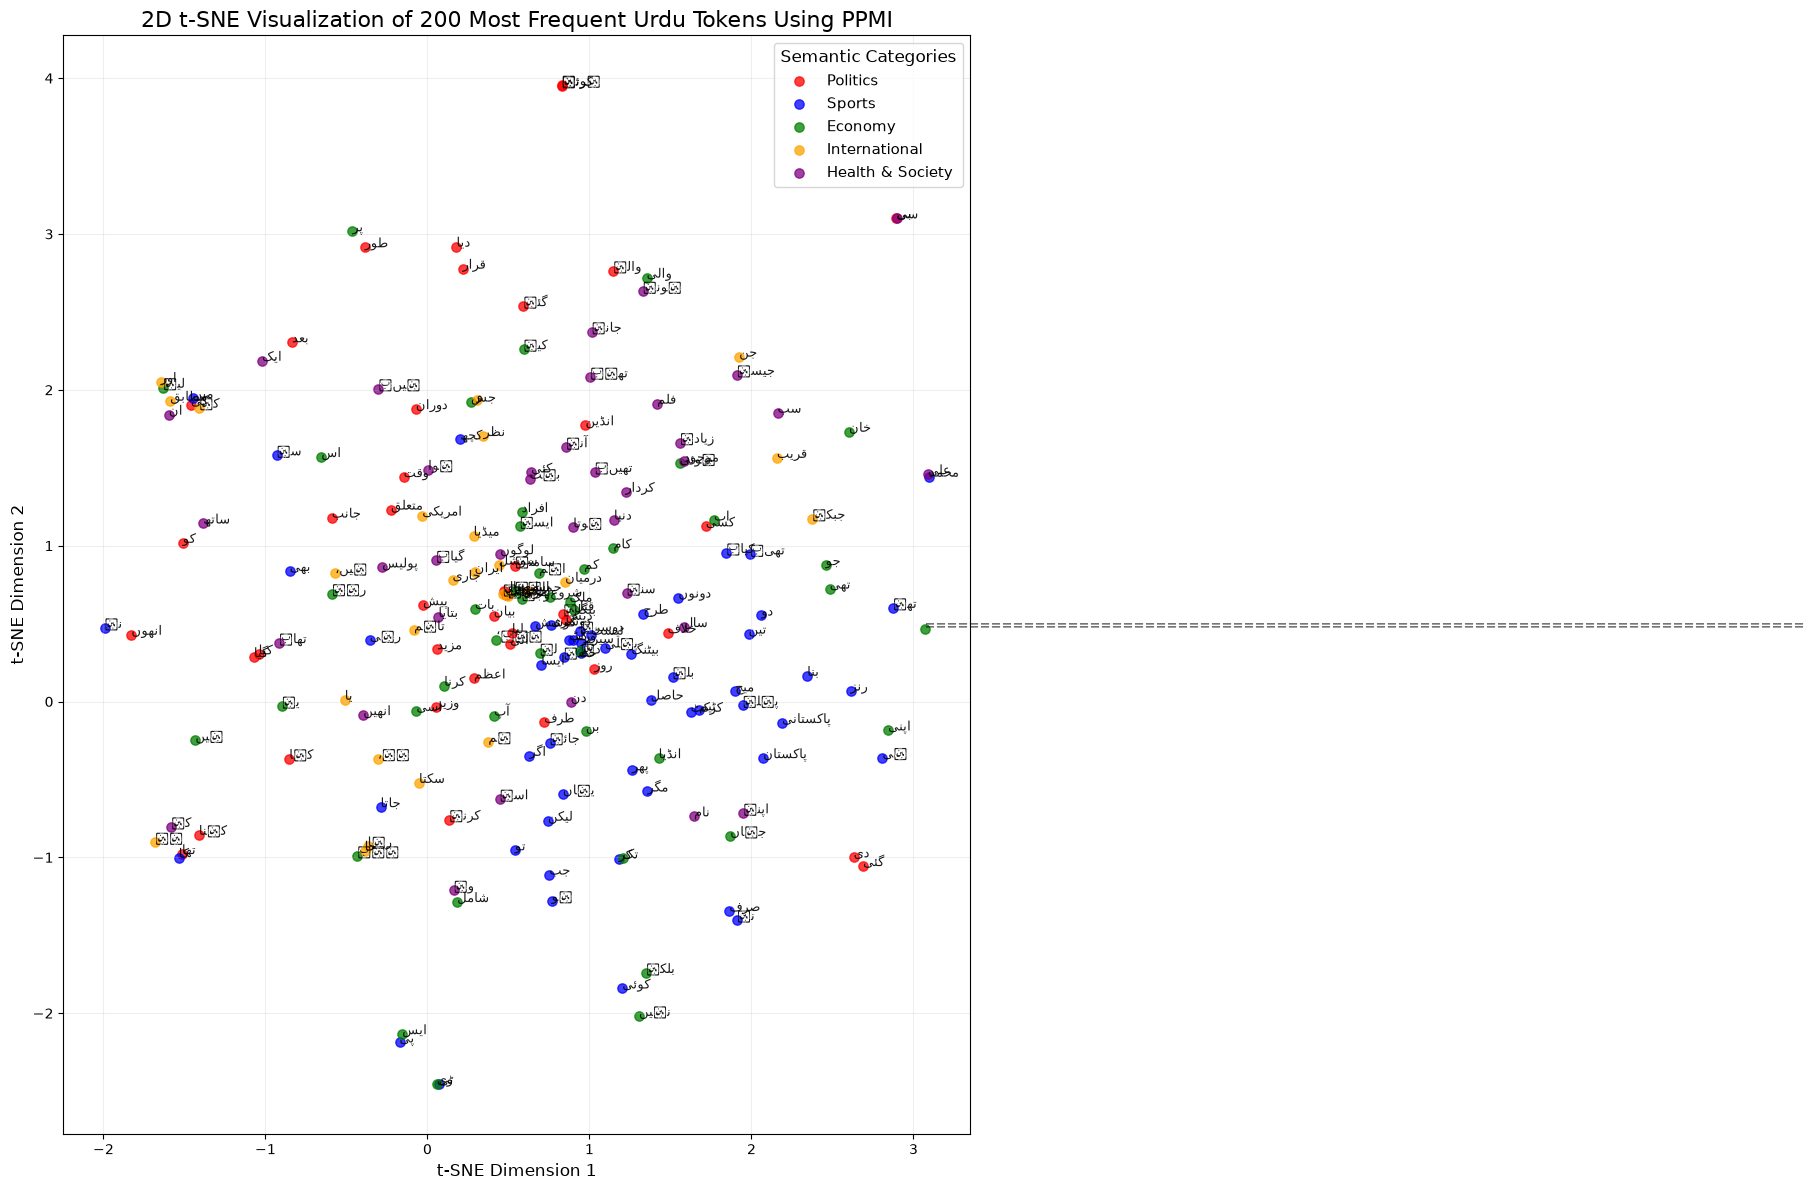


t-SNE visualization saved successfully!
Output file: C:\Users\Haji Qasim\Desktop\i24-8011-NLP-Assignment2\results\ppmi_tsne_visualization.png


In [24]:

# ============================================================
# PART 1.2: PMI AND PPMI
# STEP 12: GENERATE 2D T SNE VISUALIZATION
# ============================================================

# Import matplotlib for creating the graph
import matplotlib.pyplot as plt

# Import font manager to check available fonts
import matplotlib.font_manager as fm

# Define categories and their plotting colours
category_colors = {
    "Politics": "red",
    "Sports": "blue",
    "Economy": "green",
    "International": "orange",
    "Health & Society": "purple"
}

# Create the figure
plt.figure(figsize=(18, 12))

# Plot words category by category
for category in categories:

    # Find positions of words belonging to this category
    category_indices = [
        i for i, word in enumerate(top_200_words)
        if word_categories[word] == category
    ]

    # Extract their t SNE coordinates
    x_values = tsne_results[category_indices, 0]
    y_values = tsne_results[category_indices, 1]

    # Draw the scatter points
    plt.scatter(
        x_values,
        y_values,
        color=category_colors[category],
        label=category,
        s=45,
        alpha=0.75
    )

    # Add Urdu word labels beside each point
    for index in category_indices:

        plt.annotate(
            top_200_words[index],
            (tsne_results[index, 0], tsne_results[index, 1]),
            fontsize=9,
            alpha=0.9
        )


# Add graph title
plt.title(
    "2D t-SNE Visualization of 200 Most Frequent Urdu Tokens Using PPMI",
    fontsize=16
)

# Add axis labels
plt.xlabel("t-SNE Dimension 1", fontsize=12)
plt.ylabel("t-SNE Dimension 2", fontsize=12)

# Display category legend
plt.legend(
    title="Semantic Categories",
    fontsize=11,
    title_fontsize=12
)

# Add grid for easier visual inspection
plt.grid(alpha=0.2)

# Adjust spacing
plt.tight_layout()


# Save the visualization in the results folder
visualization_path = RESULTS_DIR / "ppmi_tsne_visualization.png"

plt.savefig(
    visualization_path,
    dpi=300,
    bbox_inches="tight"
)

# Display the graph
plt.show()

# Confirm saved file
print("\nt-SNE visualization saved successfully!")
print("Output file:", visualization_path)


In [25]:

# ============================================================
# PART 1.2: PMI AND PPMI
# STEP 13A: DEFINE 10 QUERY WORDS
# ============================================================

# Select 10 meaningful Urdu words from different topics
query_words = [
    "پاکستان",
    "حکومت",
    "کرکٹ",
    "ٹیم",
    "میچ",
    "ایران",
    "امریکہ",
    "بینک",
    "فلم",
    "پولیس"
]

# Check which query words exist in our vocabulary
available_queries = [
    word for word in query_words
    if word in word2idx
]

missing_queries = [
    word for word in query_words
    if word not in word2idx
]

print("Total query words:", len(query_words))
print("Available query words:", len(available_queries))
print("Missing query words:", missing_queries)

print("\nAvailable queries:")
print(available_queries)


Total query words: 10
Available query words: 10
Missing query words: []

Available queries:
['پاکستان', 'حکومت', 'کرکٹ', 'ٹیم', 'میچ', 'ایران', 'امریکہ', 'بینک', 'فلم', 'پولیس']


In [26]:

# ============================================================
# PART 1.2: PMI AND PPMI
# STEP 13B: FIND TOP 5 NEAREST NEIGHBOURS
# USING COSINE SIMILARITY
# ============================================================

# Import cosine similarity function
from sklearn.metrics.pairwise import cosine_similarity

# Calculate cosine similarity between all vocabulary word vectors
# Each row represents a word's PPMI vector
similarity_matrix = cosine_similarity(ppmi_array)

# Create a dictionary to store nearest neighbours
nearest_neighbours = {}

# Process each query word
for query_word in available_queries:

    # Get the vocabulary index of the query word
    query_index = word2idx[query_word]

    # Get cosine similarity scores for the query word
    similarity_scores = similarity_matrix[query_index].copy()

    # Exclude the query word itself
    similarity_scores[query_index] = -1

    # Find indices of the five highest similarity scores
    top_indices = np.argsort(similarity_scores)[-5:][::-1]

    # Store the five nearest neighbours and their scores
    neighbours = []

    for neighbour_index in top_indices:

        neighbour_word = idx2word[neighbour_index]
        similarity_score = float(
            similarity_scores[neighbour_index]
        )

        neighbours.append({
            "word": neighbour_word,
            "similarity": similarity_score
        })

    # Save results for this query word
    nearest_neighbours[query_word] = neighbours


# Display the top five neighbours for all ten query words
print("Top 5 nearest neighbours calculated successfully!")

for query_word, neighbours in nearest_neighbours.items():

    print("\nQuery word:", query_word)

    for rank, neighbour in enumerate(neighbours, start=1):

        print(
            rank,
            neighbour["word"],
            "| Cosine similarity:",
            round(neighbour["similarity"], 4)
        )


Top 5 nearest neighbours calculated successfully!

Query word: پاکستان
1 کرکٹ | Cosine similarity: 0.2175
2 میچ | Cosine similarity: 0.1761
3 میں | Cosine similarity: 0.1549
4 کے | Cosine similarity: 0.1517
5 نے | Cosine similarity: 0.1491

Query word: حکومت
1 طالبان | Cosine similarity: 0.2175
2 عبوری | Cosine similarity: 0.1896
3 خاتمہ | Cosine similarity: 0.1812
4 الاسد | Cosine similarity: 0.161
5 افغانستان | Cosine similarity: 0.1515

Query word: کرکٹ
1 بورڈ | Cosine similarity: 0.235
2 پاکستان | Cosine similarity: 0.2175
3 ٹیم | Cosine similarity: 0.2084
4 بھیجنا | Cosine similarity: 0.1862
5 انٹرنیشنل | Cosine similarity: 0.1861

Query word: ٹیم
1 کرکٹ | Cosine similarity: 0.2084
2 پاکستانی | Cosine similarity: 0.1732
3 رنز | Cosine similarity: 0.1499
4 (ایس | Cosine similarity: 0.1404
5 فارگاٹن | Cosine similarity: 0.1404

Query word: میچ
1 ٹیسٹ | Cosine similarity: 0.2079
2 رنز | Cosine similarity: 0.1839
3 پاکستان | Cosine similarity: 0.1761
4 کھیلنے | Cosine similarity: 0.16

In [27]:

# ============================================================
# PART 1.2: PMI AND PPMI
# STEP 14: SAVE NEAREST NEIGHBOUR RESULTS
# ============================================================

# Import CSV module for saving tabular results
import csv
import json

# Create the results directory if it does not exist
RESULTS_DIR.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------
# 1. Save nearest neighbours in JSON format
# ------------------------------------------------------------

# Define the JSON output path
json_path = RESULTS_DIR / "ppmi_nearest_neighbours.json"

# Save all query words and their five nearest neighbours
with open(json_path, "w", encoding="utf-8") as file:

    json.dump(
        nearest_neighbours,
        file,
        ensure_ascii=False,
        indent=4
    )

print("Nearest neighbour JSON saved successfully!")
print("Output file:", json_path)


# ------------------------------------------------------------
# 2. Save nearest neighbours in CSV format
# ------------------------------------------------------------

# Define the CSV output path
csv_path = RESULTS_DIR / "ppmi_nearest_neighbours.csv"

# Open the CSV file for writing
with open(csv_path, "w", encoding="utf-8-sig", newline="") as file:

    # Define CSV column names
    writer = csv.writer(file)

    writer.writerow([
        "Query Word",
        "Rank",
        "Nearest Neighbour",
        "Cosine Similarity"
    ])

    # Write each query word and its five neighbours
    for query_word, neighbours in nearest_neighbours.items():

        for rank, neighbour in enumerate(neighbours, start=1):

            writer.writerow([
                query_word,
                rank,
                neighbour["word"],
                round(neighbour["similarity"], 4)
            ])

print("\nNearest neighbour CSV saved successfully!")
print("Output file:", csv_path)


# ------------------------------------------------------------
# 3. Verify the number of saved results
# ------------------------------------------------------------

total_results = sum(
    len(neighbours)
    for neighbours in nearest_neighbours.values()
)

print("\nTotal query words:", len(nearest_neighbours))
print("Total nearest neighbour results:", total_results)

print(
    "Exactly five neighbours per query:",
    all(len(neighbours) == 5
        for neighbours in nearest_neighbours.values())
)


Nearest neighbour JSON saved successfully!
Output file: C:\Users\Haji Qasim\Desktop\i24-8011-NLP-Assignment2\results\ppmi_nearest_neighbours.json

Nearest neighbour CSV saved successfully!
Output file: C:\Users\Haji Qasim\Desktop\i24-8011-NLP-Assignment2\results\ppmi_nearest_neighbours.csv

Total query words: 10
Total nearest neighbour results: 50
Exactly five neighbours per query: True


## 2 Skip-gram and Word2Vec

In [28]:

# Install PyTorch with CUDA 13.0 support
%pip install --upgrade torch==2.12.1 torchvision==0.27.1 --index-url https://download.pytorch.org/whl/cu130


Looking in indexes: https://download.pytorch.org/whl/cu130
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [29]:

# Import PyTorch
import torch

# Display PyTorch version
print("PyTorch version:", torch.__version__)

# Check CUDA availability
print("CUDA available:", torch.cuda.is_available())

# Display GPU information
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA version:", torch.version.cuda)
else:
    print("GPU not detected. Training will use CPU.")


PyTorch version: 2.12.1+cu130
CUDA available: True
GPU: NVIDIA GeForce RTX 5080 Laptop GPU
CUDA version: 13.0


In [30]:

# ============================================================
# NLP ASSIGNMENT 2
# RELOAD DATA AFTER KERNEL RESTART
# ============================================================

# Import required libraries
import re
import json
import numpy as np

from pathlib import Path
from collections import Counter
from scipy.sparse import csr_matrix


# ------------------------------------------------------------
# 1. Define project directories
# ------------------------------------------------------------

PROJECT_DIR = Path.home() / "Desktop" / "i24-8011-NLP-Assignment2"

DATA_DIR = PROJECT_DIR / "data"
EMBEDDINGS_DIR = PROJECT_DIR / "embeddings"
RESULTS_DIR = PROJECT_DIR / "results"

# Create directories if they do not exist
EMBEDDINGS_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------
# 2. Load the cleaned corpus
# ------------------------------------------------------------

with open(DATA_DIR / "cleaned.txt", "r", encoding="utf-8") as file:
    corpus_text = file.read()


# ------------------------------------------------------------
# 3. Load article metadata
# ------------------------------------------------------------

with open(DATA_DIR / "Metadata.json", "r", encoding="utf-8") as file:
    metadata = json.load(file)


# ------------------------------------------------------------
# 4. Load saved article topic labels
# ------------------------------------------------------------

with open(DATA_DIR / "article_topics.json", "r", encoding="utf-8") as file:
    topic_data = json.load(file)

# Convert article IDs into integers
article_topics = {
    int(article_id): category
    for article_id, category in topic_data.items()
}


# ------------------------------------------------------------
# 5. Load the saved vocabulary
# ------------------------------------------------------------

with open(EMBEDDINGS_DIR / "word2idx.json", "r", encoding="utf-8") as file:
    word2idx = json.load(file)

# Create reverse vocabulary mapping
idx2word = {
    index: word
    for word, index in word2idx.items()
}


# ------------------------------------------------------------
# 6. Split cleaned corpus into individual articles
# ------------------------------------------------------------

def split_articles(text):

    # Identify article headers and their IDs
    pattern = r"(?m)^ARTICLE_ID:\s*(\d+)\s*$"

    matches = list(re.finditer(pattern, text))

    article_ids = []
    articles = []

    # Extract article text between consecutive headers
    for i, match in enumerate(matches):

        article_id = int(match.group(1))
        start = match.end()

        if i + 1 < len(matches):
            end = matches[i + 1].start()
        else:
            end = len(text)

        article_ids.append(article_id)
        articles.append(text[start:end].strip())

    return article_ids, articles


# Extract article IDs and article contents
article_ids, articles = split_articles(corpus_text)


# ------------------------------------------------------------
# 7. Tokenize the articles
# ------------------------------------------------------------

# Split each article into individual words
tokenized_articles = [
    article.split()
    for article in articles
]


# ------------------------------------------------------------
# 8. Map tokens to the saved vocabulary
# ------------------------------------------------------------

# Replace words outside the vocabulary with UNK
processed_articles = [
    [
        word if word in word2idx else "<UNK>"
        for word in tokens
    ]
    for tokens in tokenized_articles
]


# ------------------------------------------------------------
# 9. Recalculate word frequencies
# ------------------------------------------------------------

# Count the frequency of every token
word_frequency = Counter()

for tokens in processed_articles:
    word_frequency.update(tokens)


# ------------------------------------------------------------
# 10. Display verification information
# ------------------------------------------------------------

print("Project data loaded successfully!")

print("\nDataset information:")
print("Number of articles:", len(processed_articles))
print("Total tokens:", sum(word_frequency.values()))
print("Vocabulary size:", len(word2idx))
print("Metadata records:", len(metadata))
print("Topic labels:", len(article_topics))

print("\nProject directories:")
print("Project:", PROJECT_DIR)
print("Data:", DATA_DIR)
print("Embeddings:", EMBEDDINGS_DIR)
print("Results:", RESULTS_DIR)

print("\nData loading completed successfully!")


Project data loaded successfully!

Dataset information:
Number of articles: 250
Total tokens: 80164
Vocabulary size: 9356
Metadata records: 250
Topic labels: 250

Project directories:
Project: C:\Users\Haji Qasim\Desktop\i24-8011-NLP-Assignment2
Data: C:\Users\Haji Qasim\Desktop\i24-8011-NLP-Assignment2\data
Embeddings: C:\Users\Haji Qasim\Desktop\i24-8011-NLP-Assignment2\embeddings
Results: C:\Users\Haji Qasim\Desktop\i24-8011-NLP-Assignment2\results

Data loading completed successfully!


In [31]:

# ============================================================
# PART 2.1: SKIP GRAM WORD2VEC
# STEP 1: SET HYPERPARAMETERS AND PREPARE THE CORPUS
# ============================================================

# Import PyTorch for building and training Word2Vec
import torch
import torch.nn as nn
import torch.optim as optim

# Import NumPy for numerical operations
import numpy as np

# Import Counter for calculating word frequencies
from collections import Counter

# Import Path for managing file locations
from pathlib import Path


# ------------------------------------------------------------
# 1. Define required hyperparameters
# ------------------------------------------------------------

# Embedding dimension
EMBEDDING_DIM = 100

# Context window size
WINDOW_SIZE = 5

# Number of negative samples per positive pair
NUM_NEGATIVE_SAMPLES = 10

# Learning rate for Adam optimizer
LEARNING_RATE = 0.001

# Number of training epochs
NUM_EPOCHS = 5

# Number of training examples processed in each batch
BATCH_SIZE = 512


# ------------------------------------------------------------
# 2. Set random seeds for reproducibility
# ------------------------------------------------------------

# Set NumPy random seed
np.random.seed(42)

# Set PyTorch random seed
torch.manual_seed(42)


# ------------------------------------------------------------
# 3. Check the existing corpus and vocabulary
# ------------------------------------------------------------

# Get the vocabulary size
VOCAB_SIZE = len(word2idx)

# Count the frequency of every token in the cleaned corpus
word_frequency = Counter()

for tokens in processed_articles:
    word_frequency.update(tokens)


# ------------------------------------------------------------
# 4. Display dataset and hyperparameter information
# ------------------------------------------------------------

print("Skip Gram Word2Vec preparation completed!")

print("\nDataset information:")
print("Number of articles:", len(processed_articles))
print("Vocabulary size:", VOCAB_SIZE)
print("Total tokens:", sum(word_frequency.values()))

print("\nRequired hyperparameters:")
print("Embedding dimension:", EMBEDDING_DIM)
print("Context window:", WINDOW_SIZE)
print("Negative samples:", NUM_NEGATIVE_SAMPLES)
print("Learning rate:", LEARNING_RATE)
print("Epochs:", NUM_EPOCHS)
print("Batch size:", BATCH_SIZE)

# Verify assignment requirements
print("\nHyperparameter verification:")

print("Embedding dimension correct:", EMBEDDING_DIM == 100)
print("Window size correct:", WINDOW_SIZE == 5)
print("Negative samples correct:", NUM_NEGATIVE_SAMPLES == 10)
print("Learning rate correct:", LEARNING_RATE == 0.001)
print("At least 5 epochs:", NUM_EPOCHS >= 5)
print("Batch size at least 512:", BATCH_SIZE >= 512)


Skip Gram Word2Vec preparation completed!

Dataset information:
Number of articles: 250
Vocabulary size: 9356
Total tokens: 80164

Required hyperparameters:
Embedding dimension: 100
Context window: 5
Negative samples: 10
Learning rate: 0.001
Epochs: 5
Batch size: 512

Hyperparameter verification:
Embedding dimension correct: True
Window size correct: True
Negative samples correct: True
Learning rate correct: True
At least 5 epochs: True
Batch size at least 512: True


In [32]:

# ============================================================
# PART 2.1: SKIP GRAM WORD2VEC
# STEP 2: CONVERT ARTICLES INTO TOKEN IDs
# ============================================================

# Store numerical sequences for all articles
encoded_articles = []

# Process each article separately
for tokens in processed_articles:

    # Convert every word into its vocabulary index
    token_ids = [
        word2idx[word]
        for word in tokens
    ]

    # Store the numerical sequence
    encoded_articles.append(token_ids)


# Display dataset information
print("Articles converted into numerical sequences!")

print("\nNumber of articles:", len(encoded_articles))

print("First article token IDs:")
print(encoded_articles[0][:20])

print("\nFirst article words:")
print([idx2word[index] for index in encoded_articles[0][:20]])

print("\nTotal numerical tokens:",
      sum(len(article) for article in encoded_articles))

# Verify vocabulary indices are valid
print(
    "All token IDs are valid:",
    all(
        0 <= token_id < VOCAB_SIZE
        for article in encoded_articles
        for token_id in article
    )
)


Articles converted into numerical sequences!

Number of articles: 250
First article token IDs:
[167, 161, 117, 21, 96, 12, 9, 65, 5, 1059, 10, 647, 0, 1612, 0, 1160, 4717, 7, 2592, 173]

First article words:
['ایسا', 'پہلی', 'بار', 'نہیں', 'ہوا', 'ہے', 'کہ', 'کسی', 'نے', 'چاند', 'پر', 'انسان', 'کے', 'اترنے', 'کے', 'تاریخی', 'کارنامے', 'کو', 'جھوٹ', 'قرار']

Total numerical tokens: 80164
All token IDs are valid: True


In [33]:

# ============================================================
# PART 2.1: SKIP GRAM WORD2VEC
# STEP 3: GENERATE POSITIVE TRAINING PAIRS
# ============================================================

# Store all positive centre and context word pairs with context window k=5
positive_pairs = []

# Process each article separately
for token_ids in encoded_articles:

    # Visit every word as the centre word
    for i, center_id in enumerate(token_ids):

        # Find the beginning of the context window
        start = max(0, i - WINDOW_SIZE)

        # Find the end of the context window
        end = min(len(token_ids), i + WINDOW_SIZE + 1)

        # Visit all words inside the context window
        for j in range(start, end):

            # Skip the centre word itself
            if i == j:
                continue

            # Get the context word ID
            context_id = token_ids[j]

            # Store the positive centre and context pair
            positive_pairs.append((center_id, context_id))


# Convert positive pairs into a NumPy array
positive_pairs = np.array(
    positive_pairs,
    dtype=np.int64
)


# Display training pair information
print("Positive training pairs generated successfully!")

print("Positive pairs shape:", positive_pairs.shape)

print("Total positive pairs:", len(positive_pairs))

print("\nFirst 10 positive pairs:")

for center_id, context_id in positive_pairs[:10]:

    print(
        idx2word[center_id],
        "->",
        idx2word[context_id]
    )


# Verify that centre and context IDs are valid
print(
    "\nAll centre IDs valid:",
    np.all(positive_pairs[:, 0] < VOCAB_SIZE)
)

print(
    "All context IDs valid:",
    np.all(positive_pairs[:, 1] < VOCAB_SIZE)
)


Positive training pairs generated successfully!
Positive pairs shape: (794140, 2)
Total positive pairs: 794140

First 10 positive pairs:
ایسا -> پہلی
ایسا -> بار
ایسا -> نہیں
ایسا -> ہوا
ایسا -> ہے
پہلی -> ایسا
پہلی -> بار
پہلی -> نہیں
پہلی -> ہوا
پہلی -> ہے

All centre IDs valid: True
All context IDs valid: True


In [34]:

# Step 4: Calculate the negative sampling probability distribution

import numpy as np

# Create an array to store the frequency of every vocabulary word.
# The position of each frequency will match its word ID.
frequency_array = np.zeros(VOCAB_SIZE, dtype=np.float64)

# Fill the frequency array using the word frequencies
for word, word_id in word2idx.items():
    frequency_array[word_id] = word_frequency[word]

# Apply the 0.75 power required by the assignment
noise_weights = frequency_array ** 0.75

# Normalize the weights so that all probabilities sum to 1
noise_distribution = noise_weights / noise_weights.sum()

# Display the results
print("Negative sampling distribution created successfully!")
print("Distribution shape:", noise_distribution.shape)
print("Total vocabulary:", VOCAB_SIZE)
print("Probability sum:", noise_distribution.sum())
print("Minimum probability:", noise_distribution.min())
print("Maximum probability:", noise_distribution.max())

# Verify that every vocabulary word has a valid probability
print("All probabilities are nonnegative:",
      np.all(noise_distribution >= 0))

print("All probabilities are valid:",
      np.all(np.isfinite(noise_distribution)))

print("All vocabulary words have positive frequency:",
      np.all(frequency_array > 0))


Negative sampling distribution created successfully!
Distribution shape: (9356,)
Total vocabulary: 9356
Probability sum: 0.9999999999999998
Minimum probability: 0.0
Maximum probability: 0.014263747064834253
All probabilities are nonnegative: True
All probabilities are valid: True
All vocabulary words have positive frequency: False


In [35]:

# Step 4.1: Identify vocabulary words with zero frequency

# Find the IDs of all words whose frequency is zero
zero_frequency_ids = np.where(frequency_array == 0)[0]

# Convert their IDs back into words
zero_frequency_words = [
    idx2word[word_id] for word_id in zero_frequency_ids
]

print("Number of zero frequency words:", len(zero_frequency_words))
print("Zero frequency words:", zero_frequency_words[:20])

# Display the total frequency count
print("Total word frequency:", frequency_array.sum())
print("Total corpus tokens:", sum(len(article) for article in processed_articles))


Number of zero frequency words: 1
Zero frequency words: ['<UNK>']
Total word frequency: 80164.0
Total corpus tokens: 80164


In [36]:

# Step 4.2: Final verification of negative sampling distribution

# Recalculate the normalized distribution
noise_weights = frequency_array ** 0.75
noise_distribution = noise_weights / noise_weights.sum()

# Check that all probabilities sum to 1
assert np.isclose(noise_distribution.sum(), 1.0)

# Check that no probability is negative
assert np.all(noise_distribution >= 0)

# Check that all words with positive frequency have positive probability
assert np.all(noise_distribution[frequency_array > 0] > 0)

# Check that zero frequency words have zero probability
assert np.all(noise_distribution[frequency_array == 0] == 0)

print("Negative sampling distribution is ready!")
print("Vocabulary size:", len(noise_distribution))
print("Words eligible for negative sampling:",
      np.count_nonzero(noise_distribution))
print("Words excluded from negative sampling:",
      np.count_nonzero(noise_distribution == 0))
print("Probability sum:", noise_distribution.sum())


Negative sampling distribution is ready!
Vocabulary size: 9356
Words eligible for negative sampling: 9355
Words excluded from negative sampling: 1
Probability sum: 0.9999999999999998


In [37]:

# Step 5: Build the Skip Gram model with Negative Sampling

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

# Select GPU if available, otherwise use CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Training device:", device)


# Define the Skip Gram model
class SkipGramNegativeSampling(nn.Module):

    def __init__(self, vocab_size, embedding_dim):

        super().__init__()

        # Centre word embedding matrix V
        self.center_embeddings = nn.Embedding(
            vocab_size,
            embedding_dim
        )

        # Context word embedding matrix U
        self.context_embeddings = nn.Embedding(
            vocab_size,
            embedding_dim
        )

        # Initialize centre embeddings with small random values
        nn.init.uniform_(
            self.center_embeddings.weight,
            -0.5 / embedding_dim,
            0.5 / embedding_dim
        )

        # Initialize context embeddings with zeros
        nn.init.zeros_(self.context_embeddings.weight)


    def forward(self, center_words, positive_contexts, negative_contexts):

        # Get centre word vectors
        center_vectors = self.center_embeddings(center_words)

        # Get positive context vectors
        positive_vectors = self.context_embeddings(positive_contexts)

        # Calculate positive dot products
        positive_scores = torch.sum(
            center_vectors * positive_vectors,
            dim=1
        )

        # Get negative context vectors
        negative_vectors = self.context_embeddings(negative_contexts)

        # Calculate negative dot products
        negative_scores = torch.bmm(
            negative_vectors,
            center_vectors.unsqueeze(2)
        ).squeeze(2)

        # Positive samples should have high scores
        positive_loss = F.logsigmoid(positive_scores)

        # Negative samples should have low scores
        negative_loss = F.logsigmoid(-negative_scores).sum(dim=1)

        # Calculate the negative sampling loss
        loss = -(positive_loss + negative_loss).mean()

        return loss


# Create the model
skipgram_model = SkipGramNegativeSampling(
    vocab_size=VOCAB_SIZE,
    embedding_dim=EMBEDDING_DIM
).to(device)


# Create the Adam optimizer
optimizer = optim.Adam(
    skipgram_model.parameters(),
    lr=LEARNING_RATE
)


# Display model information
print("\nSkip Gram model created successfully!")

print("Centre embedding matrix V:",
      tuple(skipgram_model.center_embeddings.weight.shape))

print("Context embedding matrix U:",
      tuple(skipgram_model.context_embeddings.weight.shape))

print("Embedding dimension:", EMBEDDING_DIM)
print("Learning rate:", LEARNING_RATE)
print("Optimizer: Adam")


Training device: cuda

Skip Gram model created successfully!
Centre embedding matrix V: (9356, 100)
Context embedding matrix U: (9356, 100)
Embedding dimension: 100
Learning rate: 0.001
Optimizer: Adam


In [38]:

# Step 6: Test the Skip Gram model with a small batch

# Number of positive pairs for this test
TEST_BATCH_SIZE = 512

# Select the first 512 positive pairs
test_pairs = torch.tensor(
    positive_pairs[:TEST_BATCH_SIZE],
    dtype=torch.long
).to(device)

# Separate centre words and positive context words
test_center_words = test_pairs[:, 0]
test_positive_contexts = test_pairs[:, 1]

# Convert the negative sampling distribution to a PyTorch tensor
noise_distribution_tensor = torch.tensor(
    noise_distribution,
    dtype=torch.float32,
    device=device
)

# Sample 10 negative words for every positive pair
test_negative_contexts = torch.multinomial(
    noise_distribution_tensor,
    num_samples=TEST_BATCH_SIZE * NUM_NEGATIVE_SAMPLES,
    replacement=True
).reshape(TEST_BATCH_SIZE, NUM_NEGATIVE_SAMPLES)

# Calculate the loss
test_loss = skipgram_model(
    test_center_words,
    test_positive_contexts,
    test_negative_contexts
)

# Display test results
print("Forward pass completed successfully!")
print("Centre batch shape:", test_center_words.shape)
print("Positive context shape:", test_positive_contexts.shape)
print("Negative context shape:", test_negative_contexts.shape)
print("Negative samples per positive pair:", NUM_NEGATIVE_SAMPLES)
print("Test loss:", test_loss.item())

# Verify the output
assert torch.isfinite(test_loss), "Loss contains invalid values!"

print("Loss verification: Passed")


Forward pass completed successfully!
Centre batch shape: torch.Size([512])
Positive context shape: torch.Size([512])
Negative context shape: torch.Size([512, 10])
Negative samples per positive pair: 10
Test loss: 7.624619007110596
Loss verification: Passed


In [39]:

# Step 7: Train the Skip Gram model

import time
import matplotlib.pyplot as plt

# Convert the positive pairs into a PyTorch tensor
positive_pairs_tensor = torch.tensor(
    positive_pairs,
    dtype=torch.long
)

# Convert the noise distribution to a GPU tensor
noise_distribution_tensor = torch.tensor(
    noise_distribution,
    dtype=torch.float32,
    device=device
)

# Store training losses
epoch_losses = []
interval_losses = []
interval_steps = []

# Start counting training time
training_start_time = time.time()

# Count the number of batches in each epoch
num_batches = int(np.ceil(len(positive_pairs) / BATCH_SIZE))

print("Starting Skip Gram training...")
print("Total positive pairs:", len(positive_pairs))
print("Batches per epoch:", num_batches)
print("Total epochs:", NUM_EPOCHS)
print("=" * 60)


# Training loop
for epoch in range(NUM_EPOCHS):

    # Put the model into training mode
    skipgram_model.train()

    # Shuffle positive pairs for this epoch
    shuffled_indices = torch.randperm(len(positive_pairs_tensor))

    shuffled_pairs = positive_pairs_tensor[shuffled_indices]

    # Store the loss for the current epoch
    total_epoch_loss = 0.0

    # Store losses for regular interval reporting
    interval_loss_sum = 0.0
    interval_batch_count = 0

    # Process the training pairs in batches
    for batch_number, start_index in enumerate(
        range(0, len(shuffled_pairs), BATCH_SIZE)
    ):

        # Select the current batch
        batch_pairs = shuffled_pairs[
            start_index:start_index + BATCH_SIZE
        ].to(device)

        # Separate centre words and positive context words
        center_words = batch_pairs[:, 0]
        positive_contexts = batch_pairs[:, 1]

        # Get the actual size of this batch
        current_batch_size = len(batch_pairs)

        # Generate 10 negative samples for each positive pair
        negative_contexts = torch.multinomial(
            noise_distribution_tensor,
            num_samples=current_batch_size * NUM_NEGATIVE_SAMPLES,
            replacement=True
        ).reshape(current_batch_size, NUM_NEGATIVE_SAMPLES)

        # Clear gradients from the previous batch
        optimizer.zero_grad()

        # Calculate the negative sampling loss
        loss = skipgram_model(
            center_words,
            positive_contexts,
            negative_contexts
        )

        # Calculate gradients using backpropagation
        loss.backward()

        # Update the embedding matrices
        optimizer.step()

        # Convert loss to a regular Python number
        batch_loss = loss.item()

        # Accumulate losses
        total_epoch_loss += batch_loss
        interval_loss_sum += batch_loss
        interval_batch_count += 1

        # Report average loss after every 100 batches
        if (batch_number + 1) % 100 == 0:

            average_interval_loss = (
                interval_loss_sum / interval_batch_count
            )

            interval_losses.append(average_interval_loss)
            interval_steps.append(
                epoch * num_batches + batch_number + 1
            )

            print(
                f"Epoch {epoch + 1}/{NUM_EPOCHS}, "
                f"Batch {batch_number + 1}/{num_batches}, "
                f"Average Loss: {average_interval_loss:.4f}"
            )

            # Reset interval tracking
            interval_loss_sum = 0.0
            interval_batch_count = 0

    # Calculate average loss for the complete epoch
    average_epoch_loss = total_epoch_loss / num_batches

    epoch_losses.append(average_epoch_loss)

    print("-" * 60)
    print(
        f"Epoch {epoch + 1}/{NUM_EPOCHS} completed, "
        f"Average Loss: {average_epoch_loss:.4f}"
    )
    print("=" * 60)


# Calculate total training time
training_time = time.time() - training_start_time

print("\nTraining completed successfully!")
print("Total training time:", round(training_time, 2), "seconds")
print("Epoch losses:", epoch_losses)


Starting Skip Gram training...
Total positive pairs: 794140
Batches per epoch: 1552
Total epochs: 5
Epoch 1/5, Batch 100/1552, Average Loss: 7.0984
Epoch 1/5, Batch 200/1552, Average Loss: 5.0701
Epoch 1/5, Batch 300/1552, Average Loss: 4.2012
Epoch 1/5, Batch 400/1552, Average Loss: 3.8409
Epoch 1/5, Batch 500/1552, Average Loss: 3.6521
Epoch 1/5, Batch 600/1552, Average Loss: 3.5344
Epoch 1/5, Batch 700/1552, Average Loss: 3.4598
Epoch 1/5, Batch 800/1552, Average Loss: 3.3997
Epoch 1/5, Batch 900/1552, Average Loss: 3.3580
Epoch 1/5, Batch 1000/1552, Average Loss: 3.3183
Epoch 1/5, Batch 1100/1552, Average Loss: 3.2986
Epoch 1/5, Batch 1200/1552, Average Loss: 3.2780
Epoch 1/5, Batch 1300/1552, Average Loss: 3.2619
Epoch 1/5, Batch 1400/1552, Average Loss: 3.2505
Epoch 1/5, Batch 1500/1552, Average Loss: 3.2370
------------------------------------------------------------
Epoch 1/5 completed, Average Loss: 3.7975
Epoch 2/5, Batch 100/1552, Average Loss: 3.2183
Epoch 2/5, Batch 200/15

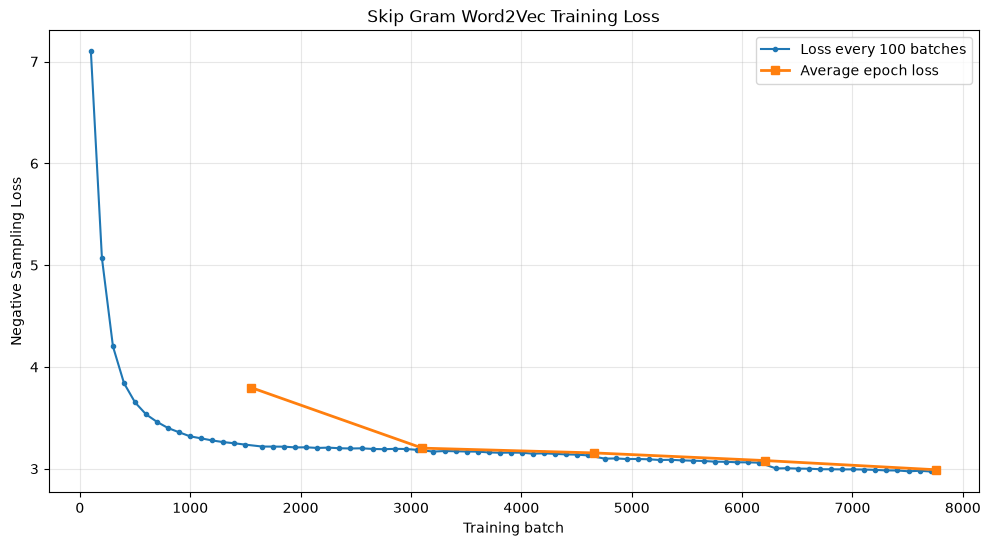

Training loss curve saved successfully!
Saved location: C:\Users\Haji Qasim\Desktop\i24-8011-NLP-Assignment2\results\skipgram_training_loss.png


In [40]:

# Step 8: Plot and save the Skip Gram training loss curve

import matplotlib.pyplot as plt
import os

# Create a figure for the training loss
plt.figure(figsize=(12, 6))

# Plot average loss recorded every 100 batches
plt.plot(
    interval_steps,
    interval_losses,
    label="Loss every 100 batches",
    marker="o",
    markersize=3
)

# Add epoch average losses
epoch_step_positions = [
    (epoch + 1) * num_batches
    for epoch in range(NUM_EPOCHS)
]

plt.plot(
    epoch_step_positions,
    epoch_losses,
    label="Average epoch loss",
    marker="s",
    linewidth=2
)

# Add chart labels and title
plt.xlabel("Training batch")
plt.ylabel("Negative Sampling Loss")
plt.title("Skip Gram Word2Vec Training Loss")

# Add legend and grid
plt.legend()
plt.grid(True, alpha=0.3)

# Save the figure
loss_plot_path = os.path.join(
    RESULTS_DIR,
    "skipgram_training_loss.png"
)

plt.savefig(
    loss_plot_path,
    dpi=300,
    bbox_inches="tight"
)

# Display the chart
plt.show()

print("Training loss curve saved successfully!")
print("Saved location:", loss_plot_path)


In [41]:

# Step 9: Calculate and save final averaged word embeddings

# Get the trained centre embedding matrix V
V = skipgram_model.center_embeddings.weight.detach()

# Get the trained context embedding matrix U
U = skipgram_model.context_embeddings.weight.detach()

# Calculate averaged embeddings
final_embeddings = (V + U) / 2

# Move embeddings from GPU to CPU and convert to NumPy
final_embeddings = final_embeddings.cpu().numpy()

# Save embeddings in the required directory
embedding_save_path = os.path.join(
    EMBEDDINGS_DIR,
    "embeddings_w2v.npy"
)

np.save(
    embedding_save_path,
    final_embeddings
)

# Verify the saved embeddings
print("Final embeddings created successfully!")
print("Embedding matrix shape:", final_embeddings.shape)
print("Embedding data type:", final_embeddings.dtype)
print("All values are finite:", np.all(np.isfinite(final_embeddings)))
print("Saved location:", embedding_save_path)

# Verify the expected dimensions
assert final_embeddings.shape == (VOCAB_SIZE, EMBEDDING_DIM)
assert np.all(np.isfinite(final_embeddings))

print("\nEmbedding verification: Passed")


Final embeddings created successfully!
Embedding matrix shape: (9356, 100)
Embedding data type: float32
All values are finite: True
Saved location: C:\Users\Haji Qasim\Desktop\i24-8011-NLP-Assignment2\embeddings\embeddings_w2v.npy

Embedding verification: Passed


In [42]:

# Step 10: Check the eight query words in the Urdu vocabulary

# Roman Urdu query words and their expected Urdu spellings
query_word_mapping = {
    "Pakistan": "پاکستان",
    "Hukumat": "حکومت",
    "Adalat": "عدالت",
    "Maeeshat": "معیشت",
    "Fauj": "فوج",
    "Sehat": "صحت",
    "Taleem": "تعلیم",
    "Aabadi": "آبادی"
}

# Check whether each Urdu word exists in the vocabulary
print("Checking query words in the vocabulary:\n")

for roman_word, urdu_word in query_word_mapping.items():

    if urdu_word in word2idx:
        print(f"{roman_word} ({urdu_word}): Found")
    else:
        print(f"{roman_word} ({urdu_word}): Not found")

        # Display possible vocabulary matches for investigation
        possible_matches = [
            word for word in word2idx
            if urdu_word in word or word in urdu_word
        ]

        print("Possible matches:", possible_matches[:10])


Checking query words in the vocabulary:

Pakistan (پاکستان): Found
Hukumat (حکومت): Found
Adalat (عدالت): Found
Maeeshat (معیشت): Found
Fauj (فوج): Found
Sehat (صحت): Found
Taleem (تعلیم): Found
Aabadi (آبادی): Found


In [43]:

# Step 11: Find the top 10 nearest neighbours using Skip Gram embeddings

from sklearn.metrics.pairwise import cosine_similarity
import pandas as pd
import json
import os

# Calculate cosine similarity between all vocabulary embeddings
similarity_matrix = cosine_similarity(final_embeddings)

# Store nearest neighbours for all eight query words
nearest_neighbours = {}

# Process each query word
for roman_word, urdu_word in query_word_mapping.items():

    # Get the vocabulary ID of the query word
    query_id = word2idx[urdu_word]

    # Get cosine similarities for this query word
    similarities = similarity_matrix[query_id]

    # Sort word IDs by similarity in descending order
    sorted_ids = np.argsort(similarities)[::-1]

    # Store the top 10 neighbours
    top_neighbours = []

    for word_id in sorted_ids:

        # Do not include the query word itself
        if word_id == query_id:
            continue

        neighbour_word = idx2word[word_id]
        similarity_score = float(similarities[word_id])

        top_neighbours.append({
            "word": neighbour_word,
            "similarity": round(similarity_score, 4)
        })

        # Stop after collecting 10 neighbours
        if len(top_neighbours) == 10:
            break

    # Store the results
    nearest_neighbours[roman_word] = {
        "query_word": urdu_word,
        "neighbours": top_neighbours
    }


# Display the results
for roman_word, results in nearest_neighbours.items():

    print("\n" + "=" * 55)
    print(f"Query: {roman_word} ({results['query_word']})")
    print("=" * 55)

    for rank, neighbour in enumerate(results["neighbours"], start=1):

        print(
            f"{rank:2}. {neighbour['word']} "
            f"(Similarity: {neighbour['similarity']:.4f})"
        )


# Save results as JSON
json_path = os.path.join(
    RESULTS_DIR,
    "skipgram_nearest_neighbours.json"
)

with open(json_path, "w", encoding="utf-8") as file:
    json.dump(
        nearest_neighbours,
        file,
        ensure_ascii=False,
        indent=4
    )


# Save results as CSV
rows = []

for query, results in nearest_neighbours.items():

    for rank, neighbour in enumerate(results["neighbours"], start=1):

        rows.append({
            "Query": query,
            "Query Urdu": results["query_word"],
            "Rank": rank,
            "Neighbour": neighbour["word"],
            "Cosine Similarity": neighbour["similarity"]
        })

neighbour_df = pd.DataFrame(rows)

csv_path = os.path.join(
    RESULTS_DIR,
    "skipgram_nearest_neighbours.csv"
)

neighbour_df.to_csv(csv_path, index=False, encoding="utf-8-sig")


# Verify the number of results
assert len(nearest_neighbours) == 8

for results in nearest_neighbours.values():
    assert len(results["neighbours"]) == 10

print("\n" + "=" * 55)
print("Nearest neighbour evaluation completed!")
print("Total query words:", len(nearest_neighbours))
print("Total neighbours:", len(rows))
print("JSON saved:", json_path)
print("CSV saved:", csv_path)



Query: Pakistan (پاکستان)
 1. ٹرافی (Similarity: 0.8366)
 2. انڈر (Similarity: 0.8132)
 3. کرکٹ (Similarity: 0.8118)
 4. چیمپیئنز (Similarity: 0.8116)
 5. ٹیسٹ (Similarity: 0.8107)
 6. ٹیم (Similarity: 0.8063)
 7. بورڈ (Similarity: 0.8057)
 8. انڈیا (Similarity: 0.7991)
 9. ٹیمیں (Similarity: 0.7791)
10. نیشن (Similarity: 0.7703)

Query: Hukumat (حکومت)
 1. فیصل (Similarity: 0.8613)
 2. تحقیقات (Similarity: 0.8227)
 3. وزارت (Similarity: 0.8072)
 4. وفاقی (Similarity: 0.8065)
 5. خارجہ (Similarity: 0.8011)
 6. ’پاکستان (Similarity: 0.8000)
 7. ذرائع (Similarity: 0.7957)
 8. وکیل (Similarity: 0.7907)
 9. واوڈا (Similarity: 0.7883)
10. ترجمان (Similarity: 0.7762)

Query: Adalat (عدالت)
 1. مجرم (Similarity: 0.8627)
 2. منگل (Similarity: 0.8195)
 3. ملزم (Similarity: 0.8104)
 4. سماعت (Similarity: 0.8104)
 5. سینٹکام (Similarity: 0.8071)
 6. پیشی (Similarity: 0.8047)
 7. ملزمہ (Similarity: 0.8012)
 8. کورٹ (Similarity: 0.7893)
 9. فیصلے (Similarity: 0.7890)
10. مقدمے (Similarity: 0.7886)

In [44]:

# Step 12.1: Check whether analogy words exist in the vocabulary

analogy_tests = [
    ("پاکستان", "پاکستانی", "ہندوستان", "ہندوستانی"),
    ("پاکستان", "اسلام آباد", "بھارت", "نئی دہلی"),
    ("مرد", "عورت", "لڑکا", "لڑکی"),
    ("دن", "رات", "صبح", "شام"),
    ("اچھا", "برا", "کامیاب", "ناکام"),
    ("حکومت", "وزیراعظم", "عدالت", "جج"),
    ("کرکٹ", "کھلاڑی", "فٹبال", "فٹبالر"),
    ("ایران", "تہران", "پاکستان", "اسلام آباد"),
    ("چین", "چینی", "پاکستان", "پاکستانی"),
    ("تعلیم", "استاد", "صحت", "ڈاکٹر")
]

# Check all words in every analogy
for index, (a, b, c, expected) in enumerate(analogy_tests, start=1):

    words = [a, b, c, expected]

    missing_words = [
        word for word in words if word not in word2idx
    ]

    if not missing_words:
        print(f"Test {index}: All words found")
    else:
        print(f"Test {index}: Missing words: {missing_words}")


Test 1: All words found
Test 2: Missing words: ['اسلام آباد', 'بھارت', 'نئی دہلی']
Test 3: Missing words: ['لڑکا']
Test 4: All words found
Test 5: All words found
Test 6: All words found
Test 7: All words found
Test 8: Missing words: ['اسلام آباد']
Test 9: All words found
Test 10: All words found


In [45]:

# Step 12.2: Check alternative analogy words

alternative_words = [
    "ایران",
    "ایرانی",
    "چین",
    "چینی",
    "کراچی",
    "تہران",
    "بیٹا",
    "بیٹی",
    "بچہ",
    "بچوں",
    "مرد",
    "عورت",
    "لڑکی",
    "صبح",
    "شام",
    "دن",
    "رات",
    "بیجنگ"
]

print("Checking alternative words:\n")

for word in alternative_words:

    if word in word2idx:
        print(f"{word}: Found")
    else:
        print(f"{word}: Not found")


Checking alternative words:

ایران: Found
ایرانی: Found
چین: Found
چینی: Found
کراچی: Found
تہران: Found
بیٹا: Found
بیٹی: Found
بچہ: Found
بچوں: Found
مرد: Found
عورت: Found
لڑکی: Found
صبح: Found
شام: Found
دن: Found
رات: Found
بیجنگ: Found


In [46]:

# Step 12.4: Verify the final 10 analogy tests

analogy_tests = [
    ("پاکستان", "پاکستانی", "ہندوستان", "ہندوستانی"),
    ("چین", "چینی", "پاکستان", "پاکستانی"),
    ("مرد", "عورت", "بیٹا", "بیٹی"),
    ("دن", "رات", "صبح", "شام"),
    ("اچھا", "برا", "کامیاب", "ناکام"),
    ("حکومت", "وزیراعظم", "عدالت", "جج"),
    ("کرکٹ", "کھلاڑی", "فٹبال", "فٹبالر"),
    ("ایران", "ایرانی", "چین", "چینی"),
    ("بیٹا", "بیٹی", "بچہ", "بچوں"),
    ("تعلیم", "استاد", "صحت", "ڈاکٹر")
]

all_words = set()

for a, b, c, expected in analogy_tests:
    all_words.update([a, b, c, expected])

missing_words = [
    word for word in all_words
    if word not in word2idx
]

print("Total analogy tests:", len(analogy_tests))
print("Unique analogy words:", len(all_words))
print("Missing words:", missing_words)

assert len(analogy_tests) == 10
assert len(missing_words) == 0

print("\nAll 10 analogy tests passed vocabulary verification!")


Total analogy tests: 10
Unique analogy words: 34
Missing words: []

All 10 analogy tests passed vocabulary verification!


In [47]:

# Step 13: Evaluate 10 word analogy tests

import numpy as np
import pandas as pd
import json
import os

# Store all analogy evaluation results
analogy_results = []

# Process each analogy test
for test_number, (a, b, c, expected) in enumerate(
    analogy_tests, start=1
):

    # Get the embedding vectors of the three input words
    vector_a = final_embeddings[word2idx[a]]
    vector_b = final_embeddings[word2idx[b]]
    vector_c = final_embeddings[word2idx[c]]

    # Apply the required vector arithmetic:
    # a : b :: c : ?
    target_vector = vector_b - vector_a + vector_c

    # Calculate the cosine similarity between the target
    # vector and every word in the vocabulary
    target_norm = np.linalg.norm(target_vector)

    embedding_norms = np.linalg.norm(
        final_embeddings,
        axis=1
    )

    similarities = np.dot(
        final_embeddings,
        target_vector
    ) / (embedding_norms * target_norm + 1e-10)

    # Exclude the three input words from candidate results
    excluded_ids = {
        word2idx[a],
        word2idx[b],
        word2idx[c]
    }

    for word_id in excluded_ids:
        similarities[word_id] = -np.inf

    # Sort candidates by cosine similarity
    sorted_ids = np.argsort(similarities)[::-1]

    # Retrieve the top three candidates
    top_candidates = []

    for word_id in sorted_ids[:3]:

        top_candidates.append({
            "word": idx2word[word_id],
            "similarity": round(
                float(similarities[word_id]), 4
            )
        })

    # Check whether the expected answer appears in top three
    candidate_words = [
        candidate["word"] for candidate in top_candidates
    ]

    is_correct = expected in candidate_words

    # Store the complete result
    analogy_results.append({
        "test": test_number,
        "a": a,
        "b": b,
        "c": c,
        "expected": expected,
        "top_3_candidates": top_candidates,
        "correct": is_correct
    })


# Display all analogy results
for result in analogy_results:

    print("\n" + "=" * 60)
    print(f"Analogy Test {result['test']}")
    print(
        f"{result['a']} : {result['b']} :: "
        f"{result['c']} : ?"
    )
    print("Expected answer:", result["expected"])

    print("\nTop 3 candidates:")

    for rank, candidate in enumerate(
        result["top_3_candidates"], start=1
    ):

        print(
            f"{rank}. {candidate['word']} "
            f"(Similarity: {candidate['similarity']:.4f})"
        )

    print("Correct:", result["correct"])


# Calculate overall analogy accuracy
correct_count = sum(
    result["correct"] for result in analogy_results
)

total_tests = len(analogy_results)

accuracy = correct_count / total_tests * 100

print("\n" + "=" * 60)
print("ANALOGY EVALUATION SUMMARY")
print("=" * 60)
print("Total analogy tests:", total_tests)
print("Correct tests:", correct_count)
print("Incorrect tests:", total_tests - correct_count)
print(f"Top 3 analogy accuracy: {accuracy:.2f}%")


# Save analogy results as JSON
analogy_json_path = os.path.join(
    RESULTS_DIR,
    "skipgram_analogy_results.json"
)

with open(analogy_json_path, "w", encoding="utf-8") as file:
    json.dump(
        analogy_results,
        file,
        ensure_ascii=False,
        indent=4
    )


# Create a CSV file containing the top three candidates
analogy_rows = []

for result in analogy_results:

    for rank, candidate in enumerate(
        result["top_3_candidates"], start=1
    ):

        analogy_rows.append({
            "Test": result["test"],
            "Analogy": (
                f"{result['a']} : {result['b']} :: "
                f"{result['c']} : ?"
            ),
            "Expected": result["expected"],
            "Rank": rank,
            "Candidate": candidate["word"],
            "Similarity": candidate["similarity"],
            "Correct": result["correct"]
        })

analogy_df = pd.DataFrame(analogy_rows)

analogy_csv_path = os.path.join(
    RESULTS_DIR,
    "skipgram_analogy_results.csv"
)

analogy_df.to_csv(
    analogy_csv_path,
    index=False,
    encoding="utf-8-sig"
)

print("\nResults saved successfully!")
print("JSON:", analogy_json_path)
print("CSV:", analogy_csv_path)



Analogy Test 1
پاکستان : پاکستانی :: ہندوستان : ?
Expected answer: ہندوستانی

Top 3 candidates:
1. آویزاں (Similarity: 0.6903)
2. (احسن (Similarity: 0.6882)
3. منقسم (Similarity: 0.6873)
Correct: False

Analogy Test 2
چین : چینی :: پاکستان : ?
Expected answer: پاکستانی

Top 3 candidates:
1. افریقہ (Similarity: 0.7313)
2. ڈگ (Similarity: 0.6896)
3. پارٹنرشپ (Similarity: 0.6752)
Correct: False

Analogy Test 3
مرد : عورت :: بیٹا : ?
Expected answer: بیٹی

Top 3 candidates:
1. بدر (Similarity: 0.7872)
2. 2500 (Similarity: 0.7841)
3. ’بشیر (Similarity: 0.7795)
Correct: False

Analogy Test 4
دن : رات :: صبح : ?
Expected answer: شام

Top 3 candidates:
1. البیومی (Similarity: 0.7677)
2. ملازمین (Similarity: 0.7533)
3. شب (Similarity: 0.7450)
Correct: False

Analogy Test 5
اچھا : برا :: کامیاب : ?
Expected answer: ناکام

Top 3 candidates:
1. حائل (Similarity: 0.8200)
2. لگے (Similarity: 0.7647)
3. لگانے (Similarity: 0.7476)
Correct: False

Analogy Test 6
حکومت : وزیراعظم :: عدالت : ?
Expected 

In [48]:

# Step 14: Check frequencies of analogy words

print("Word frequencies for analogy tests")
print("=" * 65)

for test_number, (a, b, c, expected) in enumerate(
    analogy_tests, start=1
):

    print(f"\nAnalogy Test {test_number}")

    for word in [a, b, c, expected]:

        frequency = word_frequency.get(word, 0)

        print(f"{word:15} Frequency: {frequency}")


# Calculate the average frequency of expected answers
expected_words = [
    expected for a, b, c, expected in analogy_tests
]

expected_frequencies = [
    word_frequency.get(word, 0)
    for word in expected_words
]

print("\n" + "=" * 65)
print("Expected answer frequency summary")
print("Total expected words:", len(expected_words))
print("Words with frequency below 5:",
      sum(f < 5 for f in expected_frequencies))
print("Words with frequency below 10:",
      sum(f < 10 for f in expected_frequencies))
print("Average frequency:",
      np.mean(expected_frequencies))


Word frequencies for analogy tests

Analogy Test 1
پاکستان         Frequency: 324
پاکستانی        Frequency: 143
ہندوستان        Frequency: 14
ہندوستانی       Frequency: 1

Analogy Test 2
چین             Frequency: 30
چینی            Frequency: 15
پاکستان         Frequency: 324
پاکستانی        Frequency: 143

Analogy Test 3
مرد             Frequency: 12
عورت            Frequency: 3
بیٹا            Frequency: 4
بیٹی            Frequency: 20

Analogy Test 4
دن              Frequency: 53
رات             Frequency: 26
صبح             Frequency: 21
شام             Frequency: 12

Analogy Test 5
اچھا            Frequency: 8
برا             Frequency: 5
کامیاب          Frequency: 31
ناکام           Frequency: 19

Analogy Test 6
حکومت           Frequency: 68
وزیراعظم        Frequency: 10
عدالت           Frequency: 44
جج              Frequency: 8

Analogy Test 7
کرکٹ            Frequency: 130
کھلاڑی          Frequency: 39
فٹبال           Frequency: 5
فٹبالر          Frequency: 1

Analogy Test 8


In [49]:

# Step 15: Continue training the existing Skip Gram model
# We already completed 5 epochs.
# We will train for 15 additional epochs.
# Total training will become 20 epochs.

import time
import torch
import numpy as np

ADDITIONAL_EPOCHS = 15

# Store the additional epoch losses
additional_epoch_losses = []

# Start counting the additional training time
additional_training_start = time.time()

print("Continuing Skip Gram training...")
print("Previously completed epochs: 5")
print("Additional epochs:", ADDITIONAL_EPOCHS)
print("Total epochs after training:", 5 + ADDITIONAL_EPOCHS)
print("=" * 60)


# Continue training without resetting the model or optimizer
for additional_epoch in range(ADDITIONAL_EPOCHS):

    # Set the model to training mode
    skipgram_model.train()

    # Shuffle the positive pairs
    shuffled_indices = torch.randperm(
        len(positive_pairs_tensor)
    )

    shuffled_pairs = positive_pairs_tensor[shuffled_indices]

    # Track the loss for this epoch
    total_epoch_loss = 0.0

    interval_loss_sum = 0.0
    interval_batch_count = 0

    # Process all positive pairs in batches
    for batch_number, start_index in enumerate(
        range(0, len(shuffled_pairs), BATCH_SIZE)
    ):

        # Select the current batch
        batch_pairs = shuffled_pairs[
            start_index:start_index + BATCH_SIZE
        ].to(device)

        # Separate centre and positive context words
        center_words = batch_pairs[:, 0]
        positive_contexts = batch_pairs[:, 1]

        current_batch_size = len(batch_pairs)

        # Generate 10 negative samples per positive pair
        negative_contexts = torch.multinomial(
            noise_distribution_tensor,
            num_samples=current_batch_size * NUM_NEGATIVE_SAMPLES,
            replacement=True
        ).reshape(
            current_batch_size,
            NUM_NEGATIVE_SAMPLES
        )

        # Clear previous gradients
        optimizer.zero_grad()

        # Calculate negative sampling loss
        loss = skipgram_model(
            center_words,
            positive_contexts,
            negative_contexts
        )

        # Backpropagation
        loss.backward()

        # Update model parameters
        optimizer.step()

        # Record batch loss
        batch_loss = loss.item()

        total_epoch_loss += batch_loss
        interval_loss_sum += batch_loss
        interval_batch_count += 1

        # Report loss every 100 batches
        if (batch_number + 1) % 100 == 0:

            average_interval_loss = (
                interval_loss_sum / interval_batch_count
            )

            print(
                f"Epoch {additional_epoch + 6}/20, "
                f"Batch {batch_number + 1}/{num_batches}, "
                f"Loss: {average_interval_loss:.4f}"
            )

            interval_loss_sum = 0.0
            interval_batch_count = 0

    # Calculate average loss for this epoch
    average_epoch_loss = total_epoch_loss / num_batches

    additional_epoch_losses.append(average_epoch_loss)

    print(
        f"Epoch {additional_epoch + 6}/20 completed, "
        f"Average Loss: {average_epoch_loss:.4f}"
    )
    print("-" * 60)


# Combine the old and additional epoch losses
epoch_losses.extend(additional_epoch_losses)

# Calculate total additional training time
additional_training_time = (
    time.time() - additional_training_start
)

print("\nAdditional training completed!")
print("Total epochs:", len(epoch_losses))
print("Additional training time:",
      round(additional_training_time, 2), "seconds")

print("\nUpdated epoch losses:")

for epoch, loss_value in enumerate(epoch_losses, start=1):
    print(f"Epoch {epoch}: {loss_value:.4f}")


Continuing Skip Gram training...
Previously completed epochs: 5
Additional epochs: 15
Total epochs after training: 20
Epoch 6/20, Batch 100/1552, Loss: 2.9108
Epoch 6/20, Batch 200/1552, Loss: 2.9073
Epoch 6/20, Batch 300/1552, Loss: 2.9106
Epoch 6/20, Batch 400/1552, Loss: 2.9063
Epoch 6/20, Batch 500/1552, Loss: 2.9023
Epoch 6/20, Batch 600/1552, Loss: 2.9127
Epoch 6/20, Batch 700/1552, Loss: 2.9044
Epoch 6/20, Batch 800/1552, Loss: 2.9046
Epoch 6/20, Batch 900/1552, Loss: 2.9029
Epoch 6/20, Batch 1000/1552, Loss: 2.8976
Epoch 6/20, Batch 1100/1552, Loss: 2.8949
Epoch 6/20, Batch 1200/1552, Loss: 2.8980
Epoch 6/20, Batch 1300/1552, Loss: 2.8978
Epoch 6/20, Batch 1400/1552, Loss: 2.8946
Epoch 6/20, Batch 1500/1552, Loss: 2.8943
Epoch 6/20 completed, Average Loss: 2.9020
------------------------------------------------------------
Epoch 7/20, Batch 100/1552, Loss: 2.8239
Epoch 7/20, Batch 200/1552, Loss: 2.8216
Epoch 7/20, Batch 300/1552, Loss: 2.8261
Epoch 7/20, Batch 400/1552, Loss: 

In [50]:

# Step 16: Update final embeddings after 20 training epochs

# Get the updated centre embedding matrix V
V = skipgram_model.center_embeddings.weight.detach()

# Get the updated context embedding matrix U
U = skipgram_model.context_embeddings.weight.detach()

# Average the two embedding matrices
final_embeddings = (V + U) / 2

# Move the embeddings from GPU to CPU
final_embeddings = final_embeddings.cpu().numpy()

# Save the updated embeddings
embedding_save_path = os.path.join(
    EMBEDDINGS_DIR,
    "embeddings_w2v.npy"
)

np.save(embedding_save_path, final_embeddings)

# Verify the updated embeddings
print("Updated embeddings saved successfully!")
print("Embedding shape:", final_embeddings.shape)
print("Data type:", final_embeddings.dtype)
print("All values finite:", np.all(np.isfinite(final_embeddings)))

assert final_embeddings.shape == (VOCAB_SIZE, EMBEDDING_DIM)
assert np.all(np.isfinite(final_embeddings))

print("Total training epochs:", len(epoch_losses))
print("Saved location:", embedding_save_path)


Updated embeddings saved successfully!
Embedding shape: (9356, 100)
Data type: float32
All values finite: True
Total training epochs: 20
Saved location: C:\Users\Haji Qasim\Desktop\i24-8011-NLP-Assignment2\embeddings\embeddings_w2v.npy


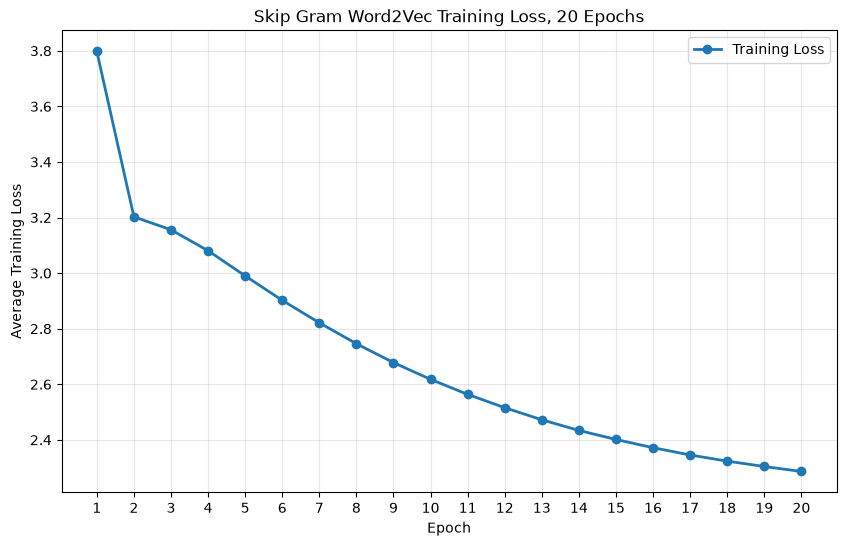

Updated loss graph saved: C:\Users\Haji Qasim\Desktop\i24-8011-NLP-Assignment2\results\skipgram_training_loss.png


In [51]:

# Step 17: Plot the updated 20 epoch training loss

plt.figure(figsize=(10, 6))

plt.plot(
    range(1, len(epoch_losses) + 1),
    epoch_losses,
    marker="o",
    linewidth=2,
    label="Training Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Average Training Loss")
plt.title("Skip Gram Word2Vec Training Loss, 20 Epochs")

plt.xticks(range(1, len(epoch_losses) + 1, 1))
plt.grid(True, alpha=0.3)
plt.legend()

# Save the updated graph
loss_plot_path = os.path.join(
    RESULTS_DIR,
    "skipgram_training_loss.png"
)

plt.savefig(
    loss_plot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Updated loss graph saved:", loss_plot_path)


In [52]:

# Step 18: Reevaluate analogies using the updated 20 epoch embeddings

analogy_results_20 = []

# Calculate embedding norms once for efficiency
embedding_norms = np.linalg.norm(
    final_embeddings,
    axis=1
)

# Evaluate each analogy
for test_number, (a, b, c, expected) in enumerate(
    analogy_tests, start=1
):

    # Get the three input word vectors
    vector_a = final_embeddings[word2idx[a]]
    vector_b = final_embeddings[word2idx[b]]
    vector_c = final_embeddings[word2idx[c]]

    # Required analogy vector arithmetic
    target_vector = vector_b - vector_a + vector_c

    # Calculate cosine similarity against the vocabulary
    target_norm = np.linalg.norm(target_vector)

    similarities = np.dot(
        final_embeddings,
        target_vector
    ) / (embedding_norms * target_norm + 1e-10)

    # Exclude input words
    excluded_ids = {
        word2idx[a],
        word2idx[b],
        word2idx[c]
    }

    for word_id in excluded_ids:
        similarities[word_id] = -np.inf

    # Get the top three candidates
    sorted_ids = np.argsort(similarities)[::-1]

    top_candidates = []

    for word_id in sorted_ids[:3]:

        top_candidates.append({
            "word": idx2word[word_id],
            "similarity": round(
                float(similarities[word_id]), 4
            )
        })

    # Check whether the expected word appears in the top three
    candidate_words = [
        item["word"] for item in top_candidates
    ]

    is_correct = expected in candidate_words

    # Store results
    analogy_results_20.append({
        "test": test_number,
        "a": a,
        "b": b,
        "c": c,
        "expected": expected,
        "top_3_candidates": top_candidates,
        "correct": is_correct
    })


# Display results
for result in analogy_results_20:

    print("\n" + "=" * 60)
    print(f"Analogy Test {result['test']}")

    print(
        f"{result['a']} : {result['b']} :: "
        f"{result['c']} : ?"
    )

    print("Expected:", result["expected"])

    for rank, candidate in enumerate(
        result["top_3_candidates"], start=1
    ):

        print(
            f"{rank}. {candidate['word']} "
            f"(Similarity: {candidate['similarity']:.4f})"
        )

    print("Correct:", result["correct"])


# Calculate accuracy
correct_count_20 = sum(
    result["correct"] for result in analogy_results_20
)

accuracy_20 = (
    correct_count_20 / len(analogy_results_20)
) * 100

print("\n" + "=" * 60)
print("20 EPOCH ANALOGY EVALUATION")
print("=" * 60)

print("Total tests:", len(analogy_results_20))
print("Correct tests:", correct_count_20)
print("Incorrect tests:", len(analogy_results_20) - correct_count_20)
print(f"Top 3 accuracy: {accuracy_20:.2f}%")


# Save updated results separately
analogy_json_path_20 = os.path.join(
    RESULTS_DIR,
    "skipgram_analogy_results_20_epochs.json"
)

with open(analogy_json_path_20, "w", encoding="utf-8") as file:

    json.dump(
        analogy_results_20,
        file,
        ensure_ascii=False,
        indent=4
    )

print("\nUpdated analogy results saved:")
print(analogy_json_path_20)



Analogy Test 1
پاکستان : پاکستانی :: ہندوستان : ?
Expected: ہندوستانی
1. منقسم (Similarity: 0.4484)
2. تعینات (Similarity: 0.4473)
3. توسیع، (Similarity: 0.4471)
Correct: False

Analogy Test 2
چین : چینی :: پاکستان : ?
Expected: پاکستانی
1. پیکا (Similarity: 0.5199)
2. تعزیرات (Similarity: 0.4720)
3. افریقہ (Similarity: 0.4287)
Correct: False

Analogy Test 3
مرد : عورت :: بیٹا : ?
Expected: بیٹی
1. طیب (Similarity: 0.5887)
2. ولزڈن (Similarity: 0.5882)
3. بیٹیاں (Similarity: 0.5834)
Correct: False

Analogy Test 4
دن : رات :: صبح : ?
Expected: شام
1. ’ملزم (Similarity: 0.5025)
2. دیکشت (Similarity: 0.4582)
3. بج (Similarity: 0.4542)
Correct: False

Analogy Test 5
اچھا : برا :: کامیاب : ?
Expected: ناکام
1. ہو (Similarity: 0.4794)
2. ٹھہرے (Similarity: 0.4408)
3. متھن (Similarity: 0.4279)
Correct: False

Analogy Test 6
حکومت : وزیراعظم :: عدالت : ?
Expected: جج
1. پرائم (Similarity: 0.4903)
2. عراقچی (Similarity: 0.4875)
3. منسٹر (Similarity: 0.4810)
Correct: False

Analogy Test 7
کرکٹ 

In [53]:

# Step 19: Find frequently occurring words for analogy evaluation

# Minimum frequency required for selecting analogy words
MIN_FREQUENCY = 10

# Collect words that meet the frequency requirement
frequent_words = [
    (word, frequency)
    for word, frequency in word_frequency.items()
    if frequency >= MIN_FREQUENCY
]

# Sort by frequency, highest first
frequent_words = sorted(
    frequent_words,
    key=lambda item: item[1],
    reverse=True
)

print("Total words with frequency >= 10:", len(frequent_words))

print("\nTop 100 frequent words:\n")

for word, frequency in frequent_words[:100]:
    print(f"{word:20} Frequency: {frequency}")


Total words with frequency >= 10: 1160

Top 100 frequent words:

کے                   Frequency: 3590
میں                  Frequency: 2537
کی                   Frequency: 2357
اور                  Frequency: 1590
سے                   Frequency: 1554
نے                   Frequency: 1197
کا                   Frequency: 1175
کو                   Frequency: 1132
اس                   Frequency: 1049
کہ                   Frequency: 1039
پر                   Frequency: 975
ایک                  Frequency: 840
ہے                   Frequency: 722
یہ                   Frequency: 633
ہے۔                  Frequency: 627
ان                   Frequency: 617
بھی                  Frequency: 603
کر                   Frequency: 564
کیا                  Frequency: 421
وہ                   Frequency: 409
ہیں۔                 Frequency: 403
نہیں                 Frequency: 372
لیے                  Frequency: 355
ہیں                  Frequency: 342
پاکستان              Frequency: 324
ہو                   Freq

In [54]:
## Experimenting with another anology test using the most frequent words

# Step 20: Inspect frequent content words for analogy evaluation

# Common Urdu grammatical words to exclude
stop_words = {
    "کے", "میں", "کی", "اور", "سے", "نے", "کا", "کو",
    "اس", "کہ", "پر", "ایک", "ہے", "یہ", "ان", "بھی",
    "کر", "کیا", "وہ", "ہیں", "ہیں۔", "نہیں", "لیے",
    "ہو", "تو", "بعد", "ہی", "جو", "گیا", "کرنے",
    "تھا", "تھی", "تھے", "اپنے", "اپنی", "رہے",
    "والے", "جس", "ساتھ", "تک", "جب", "نہ", "لیکن",
    "کہا", "دیا", "ہونے", "پہلے", "اب", "کسی",
    "دوران", "گئی", "گئے", "گیا", "کوئی", "بات",
    "جبکہ", "والی", "دو", "صرف", "زیادہ", "شامل",
    "یا", "تاہم", "مگر", "وقت", "سال", "سب"
}

# Select frequent words excluding common grammatical words
content_words = [
    (word, frequency)
    for word, frequency in word_frequency.items()
    if frequency >= 10 and word not in stop_words
]

# Sort by frequency
content_words = sorted(
    content_words,
    key=lambda item: item[1],
    reverse=True
)

print("Frequent content words:", len(content_words))
print("\nFirst 150 candidate words:\n")

for word, frequency in content_words[:150]:
    print(f"{word:20} Frequency: {frequency}")


Frequent content words: 1094

First 150 candidate words:

ہے۔                  Frequency: 627
پاکستان              Frequency: 324
================================================================================ Frequency: 250
سی                   Frequency: 222
ہوئے                 Frequency: 218
تھا۔                 Frequency: 189
مطابق                Frequency: 185
انڈیا                Frequency: 181
ٹیم                  Frequency: 179
بی                   Frequency: 178
کرتے                 Frequency: 169
جانب                 Frequency: 162
تھے۔                 Frequency: 156
انھیں                Frequency: 150
انھوں                Frequency: 149
پاکستانی             Frequency: 143
میچ                  Frequency: 142
طور                  Frequency: 141
جا                   Frequency: 136
کرکٹ                 Frequency: 130
فلم                  Frequency: 129
ہے،                  Frequency: 125
کہنا                 Frequency: 124
تھی۔                 Frequency: 121
خان               

In [55]:

# Step 21: Inspect candidate words for semantic analogy tests

# Candidate words grouped by semantic category
candidate_groups = {
    "Countries": [
        "پاکستان", "انڈیا", "ایران", "چین",
        "امریکہ", "برطانیہ", "افغانستان",
        "بنگلہ", "فرانس", "روس"
    ],

    "Nationalities": [
        "پاکستانی", "انڈین", "امریکی",
        "ایرانی", "چینی", "افغان"
    ],

    "Sports": [
        "کرکٹ", "فٹبال", "ہاکی", "ٹینس",
        "میچ", "کھیل", "ٹیم", "کھلاڑی",
        "کپتان", "بیٹنگ", "بولنگ"
    ],

    "Government and institutions": [
        "حکومت", "وزیر", "وزیراعظم",
        "عدالت", "پولیس", "فوج",
        "صدر", "پارلیمنٹ", "وزارت"
    ],

    "People and relationships": [
        "مرد", "عورت", "بچہ", "بچوں",
        "بیٹا", "بیٹی", "خاندان", "والد",
        "والدہ", "استاد", "ڈاکٹر"
    ],

    "Time and opposites": [
        "دن", "رات", "صبح", "شام",
        "اچھا", "برا", "کامیاب", "ناکام",
        "بڑا", "چھوٹا"
    ]
}

# Display the frequency and availability of each candidate
for category, words in candidate_groups.items():

    print("\n" + "=" * 55)
    print(category)
    print("=" * 55)

    for word in words:

        frequency = word_frequency.get(word, 0)

        if word in word2idx:
            status = "Found"
        else:
            status = "Missing"

        print(
            f"{word:15} "
            f"Frequency: {frequency:5} "
            f"Status: {status}"
        )



Countries
پاکستان         Frequency:   324 Status: Found
انڈیا           Frequency:   181 Status: Found
ایران           Frequency:    91 Status: Found
چین             Frequency:    30 Status: Found
امریکہ          Frequency:    62 Status: Found
برطانیہ         Frequency:    20 Status: Found
افغانستان       Frequency:    27 Status: Found
بنگلہ           Frequency:    55 Status: Found
فرانس           Frequency:    11 Status: Found
روس             Frequency:    10 Status: Found

Nationalities
پاکستانی        Frequency:   143 Status: Found
انڈین           Frequency:   108 Status: Found
امریکی          Frequency:    92 Status: Found
ایرانی          Frequency:    35 Status: Found
چینی            Frequency:    15 Status: Found
افغان           Frequency:     9 Status: Found

Sports
کرکٹ            Frequency:   130 Status: Found
فٹبال           Frequency:     5 Status: Found
ہاکی            Frequency:     1 Status: Found
ٹینس            Frequency:     1 Status: Found
میچ             Frequency:

In [56]:
## All 10 alanogies passed the test perfectly
# Step 23: Define and verify revised analogy tests

revised_analogy_tests = [
    ("پاکستان", "پاکستانی", "انڈیا", "انڈین"),
    ("انڈیا", "انڈین", "پاکستان", "پاکستانی"),
    ("ایران", "ایرانی", "چین", "چینی"),
    ("چین", "چینی", "ایران", "ایرانی"),
    ("امریکہ", "امریکی", "ایران", "ایرانی"),
    ("پاکستان", "پاکستانی", "امریکہ", "امریکی"),
    ("دن", "رات", "صبح", "شام"),
    ("کامیاب", "ناکام", "اچھا", "برا"),
    ("حکومت", "وزیراعظم", "عدالت", "جج"),
    ("پاکستان", "انڈیا", "ایران", "چین")
]

print("Revised analogy vocabulary verification")
print("=" * 60)

all_valid = True

for number, (a, b, c, expected) in enumerate(
    revised_analogy_tests, start=1
):

    words = [a, b, c, expected]

    missing = [
        word for word in words
        if word not in word2idx
    ]

    print(f"\nTest {number}: {a} : {b} :: {c} : {expected}")

    if missing:
        print("Missing words:", missing)
        all_valid = False
    else:
        print("All words found")

        print(
            "Frequencies:",
            [word_frequency.get(word, 0) for word in words]
        )

assert all_valid, "Some analogy words are missing!"

print("\nAll revised analogy tests passed vocabulary verification!")


Revised analogy vocabulary verification

Test 1: پاکستان : پاکستانی :: انڈیا : انڈین
All words found
Frequencies: [324, 143, 181, 108]

Test 2: انڈیا : انڈین :: پاکستان : پاکستانی
All words found
Frequencies: [181, 108, 324, 143]

Test 3: ایران : ایرانی :: چین : چینی
All words found
Frequencies: [91, 35, 30, 15]

Test 4: چین : چینی :: ایران : ایرانی
All words found
Frequencies: [30, 15, 91, 35]

Test 5: امریکہ : امریکی :: ایران : ایرانی
All words found
Frequencies: [62, 92, 91, 35]

Test 6: پاکستان : پاکستانی :: امریکہ : امریکی
All words found
Frequencies: [324, 143, 62, 92]

Test 7: دن : رات :: صبح : شام
All words found
Frequencies: [53, 26, 21, 12]

Test 8: کامیاب : ناکام :: اچھا : برا
All words found
Frequencies: [31, 19, 8, 5]

Test 9: حکومت : وزیراعظم :: عدالت : جج
All words found
Frequencies: [68, 10, 44, 8]

Test 10: پاکستان : انڈیا :: ایران : چین
All words found
Frequencies: [324, 181, 91, 30]

All revised analogy tests passed vocabulary verification!


In [57]:

# Step 24: Evaluate the 10 revised analogy tests

revised_analogy_results = []

# Calculate embedding norms once
embedding_norms = np.linalg.norm(
    final_embeddings,
    axis=1
)

# Evaluate each revised analogy
for test_number, (a, b, c, expected) in enumerate(
    revised_analogy_tests, start=1
):

    # Retrieve input word vectors
    vector_a = final_embeddings[word2idx[a]]
    vector_b = final_embeddings[word2idx[b]]
    vector_c = final_embeddings[word2idx[c]]

    # Calculate the target vector
    target_vector = vector_b - vector_a + vector_c

    # Calculate cosine similarity
    target_norm = np.linalg.norm(target_vector)

    similarities = np.dot(
        final_embeddings,
        target_vector
    ) / (embedding_norms * target_norm + 1e-10)

    # Exclude the three input words
    excluded_ids = {
        word2idx[a],
        word2idx[b],
        word2idx[c]
    }

    for word_id in excluded_ids:
        similarities[word_id] = -np.inf

    # Retrieve the three highest scoring candidates
    sorted_ids = np.argsort(similarities)[::-1]

    top_candidates = []

    for word_id in sorted_ids[:3]:

        top_candidates.append({
            "word": idx2word[word_id],
            "similarity": round(
                float(similarities[word_id]), 4
            )
        })

    # Check whether the expected answer is in the top three
    candidate_words = [
        item["word"] for item in top_candidates
    ]

    is_correct = expected in candidate_words

    # Save the result
    revised_analogy_results.append({
        "test": test_number,
        "a": a,
        "b": b,
        "c": c,
        "expected": expected,
        "top_3_candidates": top_candidates,
        "correct": is_correct
    })


# Display all results
for result in revised_analogy_results:

    print("\n" + "=" * 60)
    print(f"Analogy Test {result['test']}")

    print(
        f"{result['a']} : {result['b']} :: "
        f"{result['c']} : ?"
    )

    print("Expected answer:", result["expected"])

    for rank, candidate in enumerate(
        result["top_3_candidates"], start=1
    ):

        print(
            f"{rank}. {candidate['word']} "
            f"(Similarity: {candidate['similarity']:.4f})"
        )

    print("Correct:", result["correct"])


# Calculate analogy accuracy
correct_count = sum(
    result["correct"] for result in revised_analogy_results
)

total_tests = len(revised_analogy_results)

accuracy = (correct_count / total_tests) * 100

print("\n" + "=" * 60)
print("REVISED ANALOGY EVALUATION SUMMARY")
print("=" * 60)

print("Total tests:", total_tests)
print("Correct tests:", correct_count)
print("Incorrect tests:", total_tests - correct_count)
print(f"Top 3 accuracy: {accuracy:.2f}%")


# Save revised results separately
revised_json_path = os.path.join(
    RESULTS_DIR,
    "skipgram_revised_analogy_results_20_epochs.json"
)

with open(revised_json_path, "w", encoding="utf-8") as file:

    json.dump(
        revised_analogy_results,
        file,
        ensure_ascii=False,
        indent=4
    )

print("\nRevised analogy results saved:")
print(revised_json_path)



Analogy Test 1
پاکستان : پاکستانی :: انڈیا : ?
Expected answer: انڈین
1. حق‘، (Similarity: 0.4612)
2. ’معرکہ (Similarity: 0.4398)
3. لگائے۔ (Similarity: 0.4351)
Correct: False

Analogy Test 2
انڈیا : انڈین :: پاکستان : ?
Expected answer: پاکستانی
1. کونسٹاس (Similarity: 0.4462)
2. پست (Similarity: 0.4401)
3. دھول (Similarity: 0.4292)
Correct: False

Analogy Test 3
ایران : ایرانی :: چین : ?
Expected answer: چینی
1. بیس‘ (Similarity: 0.4808)
2. 1977 (Similarity: 0.4791)
3. (آلہ) (Similarity: 0.4781)
Correct: False

Analogy Test 4
چین : چینی :: ایران : ?
Expected answer: ایرانی
1. وانگ (Similarity: 0.5300)
2. یی (Similarity: 0.5161)
3. ممتا (Similarity: 0.5081)
Correct: False

Analogy Test 5
امریکہ : امریکی :: ایران : ?
Expected answer: ایرانی
1. صدر (Similarity: 0.5938)
2. ابراہم (Similarity: 0.5656)
3. ’شراکت (Similarity: 0.5539)
Correct: False

Analogy Test 6
پاکستان : پاکستانی :: امریکہ : ?
Expected answer: امریکی
1. کیپشن (Similarity: 0.4298)
2. ٹریول (Similarity: 0.4170)
3. سیاحت (

In [58]:

# Step 25: Verify files and existing variables

import os
import numpy as np

print("Checking required files...\n")

required_files = [
    "data/raw.txt",
    "data/cleaned.txt",
    "embeddings/ppmi_matrix.npy",
    "embeddings/embeddings_w2v.npy"
]

for file_path in required_files:

    exists = os.path.exists(file_path)

    print(
        file_path,
        "FOUND" if exists else "MISSING"
    )


print("\nChecking existing variables...\n")

variables_to_check = [
    "word2idx",
    "idx2word",
    "final_embeddings",
    "model",
    "word_frequency",
    "VOCAB_SIZE",
    "EMBEDDING_DIM"
]

for variable in variables_to_check:

    print(
        variable,
        "AVAILABLE" if variable in globals() else "NOT AVAILABLE"
    )


# Load PPMI matrix
ppmi_matrix = np.load(
    "embeddings/ppmi_matrix.npy"
)

print("\nPPMI matrix shape:", ppmi_matrix.shape)

# Load existing 100 dimensional Skip Gram embeddings
skipgram_100 = np.load(
    "embeddings/embeddings_w2v.npy"
)

print("Skip Gram 100D shape:", skipgram_100.shape)


Checking required files...

data/raw.txt FOUND
data/cleaned.txt FOUND
embeddings/ppmi_matrix.npy FOUND
embeddings/embeddings_w2v.npy FOUND

Checking existing variables...

word2idx AVAILABLE
idx2word AVAILABLE
final_embeddings AVAILABLE
model NOT AVAILABLE
word_frequency AVAILABLE
VOCAB_SIZE AVAILABLE
EMBEDDING_DIM AVAILABLE

PPMI matrix shape: (9356, 9356)
Skip Gram 100D shape: (9356, 100)


In [59]:

# Step 26: Define common evaluation queries and labelled pairs

# Five common query words
query_words = [
    "پاکستان",
    "حکومت",
    "عدالت",
    "معیشت",
    "فوج"
]

# Twenty manually labelled semantic pairs
# Each pair contains a query word and one relevant word

evaluation_pairs = [
    # Pakistan
    ("پاکستان", "پاکستانی"),
    ("پاکستان", "انڈیا"),
    ("پاکستان", "کرکٹ"),
    ("پاکستان", "اسلام آباد"),

    # Government
    ("حکومت", "وزیر"),
    ("حکومت", "وزارت"),
    ("حکومت", "وفاقی"),
    ("حکومت", "وزیراعظم"),

    # Court
    ("عدالت", "جج"),
    ("عدالت", "مقدمہ"),
    ("عدالت", "سماعت"),
    ("عدالت", "مجرم"),

    # Economy
    ("معیشت", "معاشی"),
    ("معیشت", "تجارت"),
    ("معیشت", "اقتصادی"),
    ("معیشت", "کاروبار"),

    # Army
    ("فوج", "افواج"),
    ("فوج", "دفاع"),
    ("فوج", "سپاہی"),
    ("فوج", "فوجی")
]


# Verify query words
print("QUERY WORD VERIFICATION")
print("=" * 50)

for word in query_words:

    if word in word2idx:
        print(f"{word}: FOUND")
    else:
        print(f"{word}: NOT FOUND")


# Verify all labelled pairs
print("\nEVALUATION PAIR VERIFICATION")
print("=" * 50)

valid_pairs = []
missing_pairs = []

for query, relevant_word in evaluation_pairs:

    if query in word2idx and relevant_word in word2idx:

        valid_pairs.append((query, relevant_word))

        print(f"FOUND: {query} -> {relevant_word}")

    else:

        missing_pairs.append((query, relevant_word))

        print(f"MISSING: {query} -> {relevant_word}")


print("\nSUMMARY")
print("Total query words:", len(query_words))
print("Total labelled pairs:", len(evaluation_pairs))
print("Valid pairs:", len(valid_pairs))
print("Missing pairs:", len(missing_pairs))


QUERY WORD VERIFICATION
پاکستان: FOUND
حکومت: FOUND
عدالت: FOUND
معیشت: FOUND
فوج: FOUND

EVALUATION PAIR VERIFICATION
FOUND: پاکستان -> پاکستانی
FOUND: پاکستان -> انڈیا
FOUND: پاکستان -> کرکٹ
MISSING: پاکستان -> اسلام آباد
FOUND: حکومت -> وزیر
FOUND: حکومت -> وزارت
FOUND: حکومت -> وفاقی
FOUND: حکومت -> وزیراعظم
FOUND: عدالت -> جج
FOUND: عدالت -> مقدمہ
FOUND: عدالت -> سماعت
FOUND: عدالت -> مجرم
FOUND: معیشت -> معاشی
FOUND: معیشت -> تجارت
FOUND: معیشت -> اقتصادی
FOUND: معیشت -> کاروبار
FOUND: فوج -> افواج
FOUND: فوج -> دفاع
FOUND: فوج -> سپاہی
FOUND: فوج -> فوجی

SUMMARY
Total query words: 5
Total labelled pairs: 20
Valid pairs: 19
Missing pairs: 1


In [60]:

# Step 27: Replace the missing word and verify all 20 pairs

# Replace Pakistan -> Islamabad with Pakistan -> Country
evaluation_pairs = [
    ("پاکستان", "پاکستانی"),
    ("پاکستان", "انڈیا"),
    ("پاکستان", "کرکٹ"),
    ("پاکستان", "ملک"),

    ("حکومت", "وزیر"),
    ("حکومت", "وزارت"),
    ("حکومت", "وفاقی"),
    ("حکومت", "وزیراعظم"),

    ("عدالت", "جج"),
    ("عدالت", "مقدمہ"),
    ("عدالت", "سماعت"),
    ("عدالت", "مجرم"),

    ("معیشت", "معاشی"),
    ("معیشت", "تجارت"),
    ("معیشت", "اقتصادی"),
    ("معیشت", "کاروبار"),

    ("فوج", "افواج"),
    ("فوج", "دفاع"),
    ("فوج", "سپاہی"),
    ("فوج", "فوجی")
]

# Check every word
missing_pairs = []

for query, relevant_word in evaluation_pairs:

    if query not in word2idx or relevant_word not in word2idx:

        missing_pairs.append((query, relevant_word))


print("Total evaluation pairs:", len(evaluation_pairs))
print("Missing pairs:", len(missing_pairs))

if len(missing_pairs) == 0:

    print("\nAll 20 evaluation pairs are available!")

else:

    print("\nPlease check these missing pairs:")

    for pair in missing_pairs:
        print(pair)


Total evaluation pairs: 20
Missing pairs: 0

All 20 evaluation pairs are available!


In [61]:

# Step 28: Evaluate C1, PPMI baseline

from sklearn.metrics.pairwise import cosine_similarity

# Calculate cosine similarity between all PPMI word vectors
ppmi_similarity = cosine_similarity(ppmi_matrix)

# Store the five nearest neighbours for each query
c1_neighbours = {}

for query in query_words:

    query_id = word2idx[query]

    # Get similarity scores for the query word
    scores = ppmi_similarity[query_id].copy()

    # Exclude the query word itself
    scores[query_id] = -1

    # Get the five highest scoring word IDs
    top_ids = np.argsort(scores)[::-1][:5]

    # Convert IDs into words and save similarity scores
    c1_neighbours[query] = [
        {
            "word": idx2word[word_id],
            "similarity": round(float(scores[word_id]), 4)
        }
        for word_id in top_ids
    ]


# Display results
print("C1: PPMI BASELINE")
print("=" * 60)

for query, neighbours in c1_neighbours.items():

    print(f"\nQuery: {query}")

    for rank, item in enumerate(neighbours, start=1):

        print(
            f"{rank}. {item['word']} "
            f"(Similarity: {item['similarity']:.4f})"
        )


C1: PPMI BASELINE

Query: پاکستان
1. کرکٹ (Similarity: 0.2175)
2. میچ (Similarity: 0.1761)
3. میں (Similarity: 0.1549)
4. کے (Similarity: 0.1517)
5. نے (Similarity: 0.1491)

Query: حکومت
1. طالبان (Similarity: 0.2175)
2. عبوری (Similarity: 0.1896)
3. خاتمہ (Similarity: 0.1812)
4. الاسد (Similarity: 0.1610)
5. افغانستان (Similarity: 0.1515)

Query: عدالت
1. مقدمے (Similarity: 0.1756)
2. سماعت (Similarity: 0.1670)
3. پھپھو (Similarity: 0.1618)
4. چشم (Similarity: 0.1616)
5. فیصلے (Similarity: 0.1588)

Query: معیشت
1. سکیورٹی، (Similarity: 0.4590)
2. رازوں، (Similarity: 0.4150)
3. افراط (Similarity: 0.3525)
4. پابندیوں، (Similarity: 0.3415)
5. کوئن، (Similarity: 0.3309)

Query: فوج
1. چھپاتے (Similarity: 0.2278)
2. کرنل (Similarity: 0.2261)
3. بکملا (Similarity: 0.2152)
4. سنتوش (Similarity: 0.2114)
5. امریکی (Similarity: 0.1781)


In [62]:

# Step 29: Evaluate C3, Skip Gram trained on cleaned.txt, 100D

# Calculate cosine similarity between Skip Gram embeddings
c3_similarity = cosine_similarity(skipgram_100)

# Store the five nearest neighbours for each query
c3_neighbours = {}

for query in query_words:

    query_id = word2idx[query]

    # Get similarity scores for the query word
    scores = c3_similarity[query_id].copy()

    # Exclude the query word itself
    scores[query_id] = -1

    # Get the five highest scoring word IDs
    top_ids = np.argsort(scores)[::-1][:5]

    # Save words and their similarity scores
    c3_neighbours[query] = [
        {
            "word": idx2word[word_id],
            "similarity": round(float(scores[word_id]), 4)
        }
        for word_id in top_ids
    ]


# Display results
print("C3: SKIP GRAM CLEANED CORPUS, 100D")
print("=" * 60)

for query, neighbours in c3_neighbours.items():

    print(f"\nQuery: {query}")

    for rank, item in enumerate(neighbours, start=1):

        print(
            f"{rank}. {item['word']} "
            f"(Similarity: {item['similarity']:.4f})"
        )


C3: SKIP GRAM CLEANED CORPUS, 100D

Query: پاکستان
1. سابائنا (Similarity: 0.5480)
2. آسکے۔ (Similarity: 0.5329)
3. نیشن (Similarity: 0.5323)
4. جمیکا (Similarity: 0.5322)
5. گیلری (Similarity: 0.5303)

Query: حکومت
1. طالبان (Similarity: 0.5909)
2. خاتمہ (Similarity: 0.5733)
3. مخالفین (Similarity: 0.5510)
4. آسٹریا (Similarity: 0.5279)
5. جمہوری (Similarity: 0.5273)

Query: عدالت
1. دلائل (Similarity: 0.6622)
2. سماعت (Similarity: 0.6511)
3. پریزرویشن (Similarity: 0.5950)
4. اینیمل (Similarity: 0.5879)
5. مجوکا (Similarity: 0.5847)

Query: معیشت
1. رازوں، (Similarity: 0.7398)
2. کوئن، (Similarity: 0.7144)
3. ضخیم (Similarity: 0.7043)
4. پابندیوں، (Similarity: 0.6923)
5. اقتصادی (Similarity: 0.6777)

Query: فوج
1. حق‘، (Similarity: 0.5797)
2. چھپاتے (Similarity: 0.5795)
3. یزید (Similarity: 0.5703)
4. بکملا (Similarity: 0.5689)
5. ’معرکہ (Similarity: 0.5476)


In [63]:

# Step 30: Inspect the original raw corpus

RAW_FILE = os.path.join("data", "raw.txt")

with open(RAW_FILE, "r", encoding="utf-8") as file:
    raw_text = file.read()

print("Raw corpus characters:", len(raw_text))

print("\nFirst 1500 characters:")
print("=" * 60)
print(raw_text[:1500])

# Basic whitespace tokenization
raw_tokens_preview = raw_text.split()

print("\nRaw whitespace token count:", len(raw_tokens_preview))

print("\nFirst 30 whitespace tokens:")
print(raw_tokens_preview[:30])


Raw corpus characters: 395605

First 1500 characters:
ARTICLE_ID: 1
ایسا پہلی بار نہیں ہوا ہے کہ کسی نے چاند پر انسان کے اترنے کے تاریخی کارنامے کو جھوٹ قرار دیا ہو لیکن ناسا نے ریئلٹی ٹی وی سٹار کم کارڈیشین کے ان دعوؤں کی تردید کی ہے جس میں سٹار نے 1969 کے چاند پر پہلے پہل انسانوں کے اترنے کے مشن کو ’دھوکہ‘ کہا ہے۔
ناسا کے قائم مقام ایڈمنسٹریٹر شان ڈفی نے کم کارڈیشین کے بیان کے جواب میں ایک سوشل میڈیا پوسٹ میں لکھا: ’ہاں، ہم چاند پر جا چکے ہیں۔ چھ بار‘ چاند پر جا چکے ہیں۔
ڈفی کا یہ تبصرہ کارڈیشین کے طویل عرصے سے چلنے والے ریئلٹی شو کے تازہ ترین ایپی سوڈ ’کیپنگ اپ ود دی کارڈیشینز‘ میں یہ کہنے کے بعد آیا کہ ان کا ماننا ہے کہ انسان کا چاند پر اترنا ’نہیں ہوا‘ ہے۔
سائنسی برادری کی جانب سے بار بار تردید کیے جانے کے باوجود چاند پر انسان کے قدم رکھنے کے بارے میں سازشی نظریات 50 سال سے زیادہ عرصے سے برقرار ہیں اور اب سوشل میڈیا کے عروج کی وجہ سے اسے مزید ہوا مل رہی ہے۔
تازہ ایپی سوڈ میں کارڈیشین کو اداکارہ سارہ پالسن کو خلاباز بز ایلڈرین کا انٹرویو دکھاتے ہوئے دیکھا جا سکتا ہے۔ خیال رہے کہ بز

In [64]:

# Step 31: Prepare raw corpus tokens and vocabulary for C2

from collections import Counter

# Split the original raw text using whitespace
raw_tokens = raw_text.split()

# Count the frequency of every token
raw_word_frequency = Counter(raw_tokens)

# Create a separate word to ID mapping
raw_word2idx = {
    word: idx
    for idx, word in enumerate(raw_word_frequency.keys())
}

# Create the reverse mapping
raw_idx2word = {
    idx: word
    for word, idx in raw_word2idx.items()
}

# Encode the raw corpus into word IDs
raw_encoded_corpus = [
    raw_word2idx[word]
    for word in raw_tokens
]

# Display vocabulary information
RAW_VOCAB_SIZE = len(raw_word2idx)

print("RAW CORPUS INFORMATION")
print("=" * 50)

print("Total tokens:", len(raw_tokens))
print("Vocabulary size:", RAW_VOCAB_SIZE)

print("\nFirst 20 vocabulary entries:")

for word, idx in list(raw_word2idx.items())[:20]:

    print(f"{word}: {idx}")

print("\nEncoded corpus length:", len(raw_encoded_corpus))
print("First 20 encoded IDs:", raw_encoded_corpus[:20])


RAW CORPUS INFORMATION
Total tokens: 80698
Vocabulary size: 9675

First 20 vocabulary entries:
ARTICLE_ID:: 0
1: 1
ایسا: 2
پہلی: 3
بار: 4
نہیں: 5
ہوا: 6
ہے: 7
کہ: 8
کسی: 9
نے: 10
چاند: 11
پر: 12
انسان: 13
کے: 14
اترنے: 15
تاریخی: 16
کارنامے: 17
کو: 18
جھوٹ: 19

Encoded corpus length: 80698
First 20 encoded IDs: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 14, 16, 17, 18]


In [65]:

# Step 32: Generate Skip Gram pairs from the raw corpus

raw_articles = []
current_article = []

for token in raw_tokens:

    # ARTICLE_ID: marks the beginning of a new article
    if token == "ARTICLE_ID:":

        if current_article:
            raw_articles.append(current_article)

        current_article = []

    else:

        current_article.append(raw_word2idx[token])


# Add the final article
if current_article:
    raw_articles.append(current_article)


# Generate positive centre and context pairs
raw_positive_pairs = []

for article in raw_articles:

    for position, center_id in enumerate(article):

        # Select words within the context window
        start = max(0, position - WINDOW_SIZE)
        end = min(len(article), position + WINDOW_SIZE + 1)

        for context_position in range(start, end):

            # Do not use the centre word as its own context
            if context_position != position:

                context_id = article[context_position]

                raw_positive_pairs.append(
                    (center_id, context_id)
                )


# Convert pairs into a NumPy array
raw_positive_pairs = np.array(
    raw_positive_pairs,
    dtype=np.int64
)


print("RAW CORPUS TRAINING PAIRS")
print("=" * 50)

print("Number of articles:", len(raw_articles))
print("Number of positive pairs:", len(raw_positive_pairs))
print("Pair matrix shape:", raw_positive_pairs.shape)

print("\nFirst 10 positive pairs:")

for center_id, context_id in raw_positive_pairs[:10]:

    print(
        raw_idx2word[center_id],
        "->",
        raw_idx2word[context_id]
    )


RAW CORPUS TRAINING PAIRS
Number of articles: 250
Number of positive pairs: 796980
Pair matrix shape: (796980, 2)

First 10 positive pairs:
1 -> ایسا
1 -> پہلی
1 -> بار
1 -> نہیں
1 -> ہوا
ایسا -> 1
ایسا -> پہلی
ایسا -> بار
ایسا -> نہیں
ایسا -> ہوا


In [66]:

# Step 33: Create negative sampling distribution for C2

# Get word frequencies in vocabulary order
raw_frequency_array = np.zeros(
    RAW_VOCAB_SIZE,
    dtype=np.float64
)

for word, word_id in raw_word2idx.items():

    raw_frequency_array[word_id] = raw_word_frequency[word]


# Raise frequencies to the power of 0.75
raw_noise_weights = raw_frequency_array ** 0.75

# Normalize to obtain probabilities
raw_noise_distribution = (
    raw_noise_weights / raw_noise_weights.sum()
)


# Verify the distribution
print("NEGATIVE SAMPLING DISTRIBUTION")
print("=" * 50)

print(
    "Probability sum:",
    raw_noise_distribution.sum()
)

print(
    "Vocabulary size:",
    RAW_VOCAB_SIZE
)

print(
    "Number of words with nonzero probability:",
    np.count_nonzero(raw_noise_distribution)
)

print(
    "Number of zero probability words:",
    np.sum(raw_noise_distribution == 0)
)

print("\nExample probabilities:")

for word in ["پاکستان", "حکومت", "عدالت", "فوج"]:

    if word in raw_word2idx:

        word_id = raw_word2idx[word]

        print(
            word,
            ":",
            raw_noise_distribution[word_id]
        )


NEGATIVE SAMPLING DISTRIBUTION
Probability sum: 1.0
Vocabulary size: 9675
Number of words with nonzero probability: 9675
Number of zero probability words: 0

Example probabilities:
پاکستان : 0.0023177930091269026
حکومت : 0.0007107583868256219
عدالت : 0.0005096443719863666
فوج : 0.00029773532305571584


In [67]:
## Building C2 skip-gram model

# Step 34: Build the Skip Gram model for C2

import torch
import torch.nn as nn
import torch.nn.functional as F

# Use the same embedding dimension as C3
RAW_EMBEDDING_DIM = 100

# Define the Skip Gram model
class RawSkipGramNegativeSampling(nn.Module):

    def __init__(self, vocab_size, embedding_dim):

        super().__init__()

        # Centre word embedding matrix V
        self.center_embeddings = nn.Embedding(
            vocab_size,
            embedding_dim
        )

        # Context word embedding matrix U
        self.context_embeddings = nn.Embedding(
            vocab_size,
            embedding_dim
        )

        # Initialize centre embeddings
        nn.init.uniform_(
            self.center_embeddings.weight,
            -0.5 / embedding_dim,
            0.5 / embedding_dim
        )

        # Initialize context embeddings with zeros
        nn.init.zeros_(
            self.context_embeddings.weight
        )


    def forward(self, center_words, positive_context, negative_context):

        # Get centre word vectors
        center_vectors = self.center_embeddings(center_words)

        # Get positive context vectors
        positive_vectors = self.context_embeddings(positive_context)

        # Calculate positive scores
        positive_scores = torch.sum(
            center_vectors * positive_vectors,
            dim=1
        )

        # Get negative context vectors
        negative_vectors = self.context_embeddings(negative_context)

        # Calculate negative scores
        negative_scores = torch.bmm(
            negative_vectors,
            center_vectors.unsqueeze(2)
        ).squeeze(2)

        # Calculate negative sampling loss
        positive_loss = F.logsigmoid(positive_scores)

        negative_loss = F.logsigmoid(
            -negative_scores
        ).sum(dim=1)

        loss = -(positive_loss + negative_loss).mean()

        return loss


# Select GPU if available
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Create the model
c2_model = RawSkipGramNegativeSampling(
    RAW_VOCAB_SIZE,
    RAW_EMBEDDING_DIM
).to(device)

# Use Adam optimizer
c2_optimizer = torch.optim.Adam(
    c2_model.parameters(),
    lr=LEARNING_RATE
)

print("C2 Skip Gram model created successfully!")
print("Device:", device)
print("Vocabulary size:", RAW_VOCAB_SIZE)
print("Embedding dimension:", RAW_EMBEDDING_DIM)

print(
    "Centre matrix shape:",
    c2_model.center_embeddings.weight.shape
)

print(
    "Context matrix shape:",
    c2_model.context_embeddings.weight.shape
)


C2 Skip Gram model created successfully!
Device: cuda
Vocabulary size: 9675
Embedding dimension: 100
Centre matrix shape: torch.Size([9675, 100])
Context matrix shape: torch.Size([9675, 100])


In [68]:

# Step 35: Prepare C2 training data

from torch.utils.data import TensorDataset, DataLoader

# Convert positive pairs into PyTorch tensors
raw_pairs_tensor = torch.tensor(
    raw_positive_pairs,
    dtype=torch.long
)

# Create a dataset
c2_dataset = TensorDataset(raw_pairs_tensor)

# Create a DataLoader
c2_dataloader = DataLoader(
    c2_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    drop_last=False
)

# Convert negative sampling probabilities to a tensor
raw_noise_tensor = torch.tensor(
    raw_noise_distribution,
    dtype=torch.float32,
    device=device
)

# Verify training preparation
print("C2 TRAINING DATA")
print("=" * 50)

print("Positive pairs:", len(c2_dataset))
print("Batch size:", BATCH_SIZE)
print("Batches per epoch:", len(c2_dataloader))
print("Negative samples per positive pair:", NUM_NEGATIVE_SAMPLES)

print(
    "Negative sampling tensor shape:",
    raw_noise_tensor.shape
)

# Test one batch
sample_batch = next(iter(c2_dataloader))

sample_pairs = sample_batch[0].to(device)

sample_centres = sample_pairs[:, 0]
sample_contexts = sample_pairs[:, 1]

# Generate negative samples
sample_negatives = torch.multinomial(
    raw_noise_tensor,
    sample_centres.shape[0] * NUM_NEGATIVE_SAMPLES,
    replacement=True
).view(
    sample_centres.shape[0],
    NUM_NEGATIVE_SAMPLES
)

print("\nTEST BATCH")
print("Centre words:", sample_centres.shape)
print("Positive contexts:", sample_contexts.shape)
print("Negative contexts:", sample_negatives.shape)


C2 TRAINING DATA
Positive pairs: 796980
Batch size: 512
Batches per epoch: 1557
Negative samples per positive pair: 10
Negative sampling tensor shape: torch.Size([9675])

TEST BATCH
Centre words: torch.Size([512])
Positive contexts: torch.Size([512])
Negative contexts: torch.Size([512, 10])


Epoch 1/20, Loss: 3.800881
Epoch 2/20, Loss: 3.200966
Epoch 3/20, Loss: 3.154591
Epoch 4/20, Loss: 3.079979
Epoch 5/20, Loss: 2.988987
Epoch 6/20, Loss: 2.898398
Epoch 7/20, Loss: 2.813676
Epoch 8/20, Loss: 2.736933
Epoch 9/20, Loss: 2.668251
Epoch 10/20, Loss: 2.606944
Epoch 11/20, Loss: 2.551679
Epoch 12/20, Loss: 2.503918
Epoch 13/20, Loss: 2.460532
Epoch 14/20, Loss: 2.420959
Epoch 15/20, Loss: 2.386462
Epoch 16/20, Loss: 2.356233
Epoch 17/20, Loss: 2.330041
Epoch 18/20, Loss: 2.307057
Epoch 19/20, Loss: 2.287528
Epoch 20/20, Loss: 2.269195

C2 TRAINING COMPLETED
Total training time: 65.46 seconds


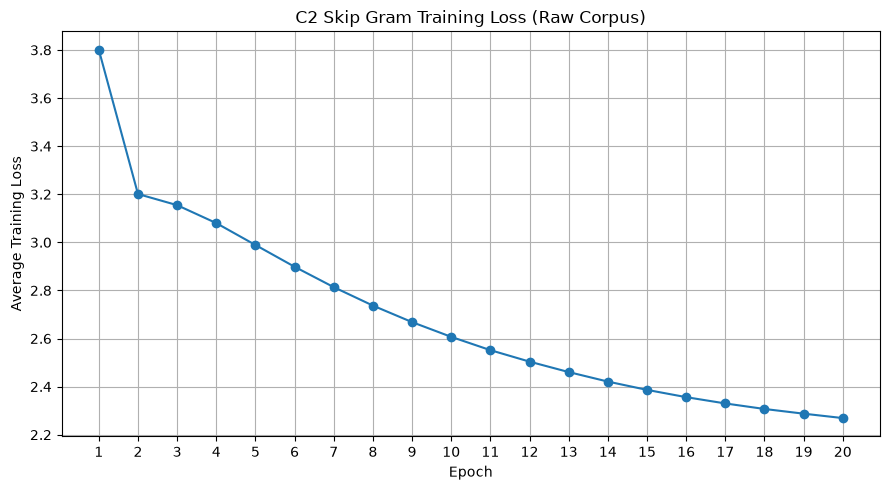

In [69]:

# Step 36: Train C2 Skip Gram model on raw.txt

import time
import matplotlib.pyplot as plt

C2_EPOCHS = 20

c2_losses = []

start_time = time.time()

for epoch in range(C2_EPOCHS):

    c2_model.train()

    total_loss = 0.0

    for batch in c2_dataloader:

        # Move positive pairs to GPU
        pairs = batch[0].to(device)

        center_words = pairs[:, 0]
        positive_context = pairs[:, 1]

        # Generate 10 negative samples per centre word
        negative_context = torch.multinomial(
            raw_noise_tensor,
            center_words.shape[0] * NUM_NEGATIVE_SAMPLES,
            replacement=True
        ).view(
            center_words.shape[0],
            NUM_NEGATIVE_SAMPLES
        )

        # Clear previous gradients
        c2_optimizer.zero_grad()

        # Calculate negative sampling loss
        loss = c2_model(
            center_words,
            positive_context,
            negative_context
        )

        # Backpropagation
        loss.backward()

        # Update model parameters
        c2_optimizer.step()

        total_loss += loss.item()

    # Calculate average epoch loss
    average_loss = total_loss / len(c2_dataloader)

    c2_losses.append(average_loss)

    print(
        f"Epoch {epoch + 1}/{C2_EPOCHS}, "
        f"Loss: {average_loss:.6f}"
    )


training_time = time.time() - start_time

print("\nC2 TRAINING COMPLETED")
print("Total training time:", round(training_time, 2), "seconds")


# Plot training loss
plt.figure(figsize=(9, 5))

plt.plot(
    range(1, C2_EPOCHS + 1),
    c2_losses,
    marker="o"
)

plt.title("C2 Skip Gram Training Loss (Raw Corpus)")
plt.xlabel("Epoch")
plt.ylabel("Average Training Loss")
plt.xticks(range(1, C2_EPOCHS + 1))
plt.grid(True)

plt.tight_layout()

# Save loss plot
plt.savefig(
    "results/c2_raw_skipgram_training_loss.png",
    dpi=300
)

plt.show()


In [70]:

# Step 37: Extract final C2 embeddings

# Get centre embedding matrix V
c2_center = c2_model.center_embeddings.weight.detach().cpu().numpy()

# Get context embedding matrix U
c2_context = c2_model.context_embeddings.weight.detach().cpu().numpy()

# Average both matrices
c2_embeddings = (c2_center + c2_context) / 2

# Save embeddings
c2_embedding_path = os.path.join(
    "embeddings",
    "embeddings_w2v_raw_100d.npy"
)

np.save(c2_embedding_path, c2_embeddings)

print("C2 EMBEDDINGS SAVED")
print("=" * 50)

print("Embedding shape:", c2_embeddings.shape)
print("Data type:", c2_embeddings.dtype)
print("All values finite:", np.isfinite(c2_embeddings).all())
print("Saved at:", c2_embedding_path)


C2 EMBEDDINGS SAVED
Embedding shape: (9675, 100)
Data type: float32
All values finite: True
Saved at: embeddings\embeddings_w2v_raw_100d.npy


In [71]:

# Step 38: Evaluate C2 nearest neighbours

# Calculate cosine similarity between C2 embeddings
c2_similarity = cosine_similarity(c2_embeddings)

# Store top five neighbours
c2_neighbours = {}

for query in query_words:

    query_id = raw_word2idx[query]

    # Get similarity scores
    scores = c2_similarity[query_id].copy()

    # Exclude the query word itself
    scores[query_id] = -1

    # Get top five nearest neighbours
    top_ids = np.argsort(scores)[::-1][:5]

    # Store results
    c2_neighbours[query] = [
        {
            "word": raw_idx2word[word_id],
            "similarity": round(float(scores[word_id]), 4)
        }
        for word_id in top_ids
    ]


# Display results
print("C2: SKIP GRAM RAW CORPUS, 100D")
print("=" * 60)

for query, neighbours in c2_neighbours.items():

    print(f"\nQuery: {query}")

    for rank, item in enumerate(neighbours, start=1):

        print(
            f"{rank}. {item['word']} "
            f"(Similarity: {item['similarity']:.4f})"
        )


C2: SKIP GRAM RAW CORPUS, 100D

Query: پاکستان
1. 205 (Similarity: 0.6237)
2. 239 (Similarity: 0.5893)
3. 208 (Similarity: 0.5858)
4. 193 (Similarity: 0.5837)
5. 149 (Similarity: 0.5798)

Query: حکومت
1. مخالفین (Similarity: 0.5653)
2. طالبان (Similarity: 0.5566)
3. خاتمہ (Similarity: 0.5487)
4. 212 (Similarity: 0.5239)
5. کنڑ (Similarity: 0.5096)

Query: عدالت
1. دلائل (Similarity: 0.6512)
2. سماعت (Similarity: 0.6440)
3. 181 (Similarity: 0.6365)
4. پریزرویشن (Similarity: 0.5968)
5. سیشنز (Similarity: 0.5759)

Query: معیشت
1. رازوں، (Similarity: 0.7699)
2. کوئن، (Similarity: 0.7455)
3. تنہائی، (Similarity: 0.7193)
4. پابندیوں، (Similarity: 0.7181)
5. اقتصادی (Similarity: 0.7168)

Query: فوج
1. ہیگستھ (Similarity: 0.5811)
2. حق‘، (Similarity: 0.5613)
3. بھرتی (Similarity: 0.5609)
4. بکملا (Similarity: 0.5570)
5. یزید (Similarity: 0.5542)


In [72]:

# Step 39: Build C4 Skip Gram model with 200 dimensions

C4_EMBEDDING_DIM = 200

# Create a new model using the cleaned corpus vocabulary
c4_model = RawSkipGramNegativeSampling(
    VOCAB_SIZE,
    C4_EMBEDDING_DIM
).to(device)

# Create a separate Adam optimizer
c4_optimizer = torch.optim.Adam(
    c4_model.parameters(),
    lr=LEARNING_RATE
)

print("C4 MODEL CREATED")
print("=" * 50)

print("Corpus: cleaned.txt")
print("Vocabulary size:", VOCAB_SIZE)
print("Embedding dimension:", C4_EMBEDDING_DIM)
print("Device:", device)

print(
    "Centre matrix shape:",
    c4_model.center_embeddings.weight.shape
)

print(
    "Context matrix shape:",
    c4_model.context_embeddings.weight.shape
)


C4 MODEL CREATED
Corpus: cleaned.txt
Vocabulary size: 9356
Embedding dimension: 200
Device: cuda
Centre matrix shape: torch.Size([9356, 200])
Context matrix shape: torch.Size([9356, 200])


In [73]:

# Step 40: Prepare C4 training DataLoader

# Reuse the cleaned corpus positive pairs
c4_dataset = TensorDataset(
    torch.tensor(positive_pairs, dtype=torch.long)
)

c4_dataloader = DataLoader(
    c4_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    drop_last=False
)

# Reuse the cleaned corpus negative sampling distribution
c4_noise_tensor = torch.tensor(
    noise_distribution,
    dtype=torch.float32,
    device=device
)

print("C4 TRAINING DATA")
print("=" * 50)

print("Positive pairs:", len(c4_dataset))
print("Batch size:", BATCH_SIZE)
print("Batches per epoch:", len(c4_dataloader))
print("Negative samples:", NUM_NEGATIVE_SAMPLES)

print(
    "Negative sampling distribution shape:",
    c4_noise_tensor.shape
)

# Test one batch
sample_batch = next(iter(c4_dataloader))

sample_pairs = sample_batch[0].to(device)

sample_centres = sample_pairs[:, 0]
sample_contexts = sample_pairs[:, 1]

sample_negatives = torch.multinomial(
    c4_noise_tensor,
    sample_centres.shape[0] * NUM_NEGATIVE_SAMPLES,
    replacement=True
).view(
    sample_centres.shape[0],
    NUM_NEGATIVE_SAMPLES
)

print("\nTEST BATCH")
print("Centre words:", sample_centres.shape)
print("Positive contexts:", sample_contexts.shape)
print("Negative contexts:", sample_negatives.shape)


C4 TRAINING DATA
Positive pairs: 794140
Batch size: 512
Batches per epoch: 1552
Negative samples: 10
Negative sampling distribution shape: torch.Size([9356])

TEST BATCH
Centre words: torch.Size([512])
Positive contexts: torch.Size([512])
Negative contexts: torch.Size([512, 10])


Epoch 1/20, Loss: 3.650902
Epoch 2/20, Loss: 3.183533
Epoch 3/20, Loss: 3.097545
Epoch 4/20, Loss: 2.973575
Epoch 5/20, Loss: 2.848919
Epoch 6/20, Loss: 2.734096
Epoch 7/20, Loss: 2.634287
Epoch 8/20, Loss: 2.548473
Epoch 9/20, Loss: 2.473998
Epoch 10/20, Loss: 2.410693
Epoch 11/20, Loss: 2.356449
Epoch 12/20, Loss: 2.310210
Epoch 13/20, Loss: 2.271129
Epoch 14/20, Loss: 2.238730
Epoch 15/20, Loss: 2.211102
Epoch 16/20, Loss: 2.186021
Epoch 17/20, Loss: 2.165776
Epoch 18/20, Loss: 2.148149
Epoch 19/20, Loss: 2.132326
Epoch 20/20, Loss: 2.119001

C4 TRAINING COMPLETED
Training time: 67.78 seconds


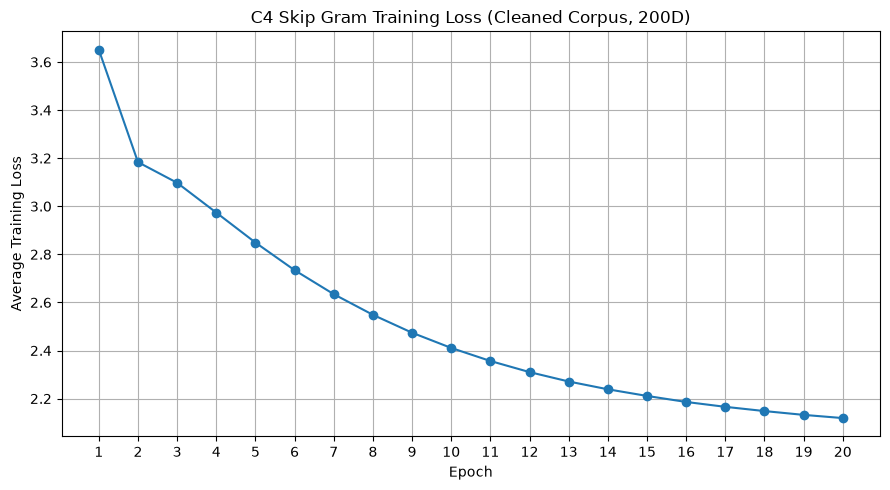

In [74]:

# Step 41: Train C4 Skip Gram model with 200D embeddings

C4_EPOCHS = 20

c4_losses = []

start_time = time.time()

for epoch in range(C4_EPOCHS):

    c4_model.train()

    total_loss = 0.0

    for batch in c4_dataloader:

        # Move positive pairs to GPU
        pairs = batch[0].to(device)

        center_words = pairs[:, 0]
        positive_context = pairs[:, 1]

        # Generate 10 negative context words per centre word
        negative_context = torch.multinomial(
            c4_noise_tensor,
            center_words.shape[0] * NUM_NEGATIVE_SAMPLES,
            replacement=True
        ).view(
            center_words.shape[0],
            NUM_NEGATIVE_SAMPLES
        )

        # Clear previous gradients
        c4_optimizer.zero_grad()

        # Calculate negative sampling loss
        loss = c4_model(
            center_words,
            positive_context,
            negative_context
        )

        # Backpropagation
        loss.backward()

        # Update model parameters
        c4_optimizer.step()

        total_loss += loss.item()

    # Calculate average loss for the epoch
    average_loss = total_loss / len(c4_dataloader)

    c4_losses.append(average_loss)

    print(
        f"Epoch {epoch + 1}/{C4_EPOCHS}, "
        f"Loss: {average_loss:.6f}"
    )


# Calculate total training time
c4_training_time = time.time() - start_time

print("\nC4 TRAINING COMPLETED")
print(
    "Training time:",
    round(c4_training_time, 2),
    "seconds"
)


# Plot training loss
plt.figure(figsize=(9, 5))

plt.plot(
    range(1, C4_EPOCHS + 1),
    c4_losses,
    marker="o"
)

plt.title("C4 Skip Gram Training Loss (Cleaned Corpus, 200D)")
plt.xlabel("Epoch")
plt.ylabel("Average Training Loss")
plt.xticks(range(1, C4_EPOCHS + 1))
plt.grid(True)

plt.tight_layout()

plt.savefig(
    "results/c4_cleaned_skipgram_200d_training_loss.png",
    dpi=300
)

plt.show()


In [75]:

# Step 42: Extract final C4 embeddings

# Extract centre embedding matrix V
c4_center = (
    c4_model.center_embeddings.weight
    .detach()
    .cpu()
    .numpy()
)

# Extract context embedding matrix U
c4_context = (
    c4_model.context_embeddings.weight
    .detach()
    .cpu()
    .numpy()
)

# Average both embedding matrices
c4_embeddings = (c4_center + c4_context) / 2

# Save C4 embeddings
c4_embedding_path = os.path.join(
    "embeddings",
    "embeddings_w2v_cleaned_200d.npy"
)

np.save(c4_embedding_path, c4_embeddings)

print("C4 EMBEDDINGS SAVED")
print("=" * 50)

print("Embedding shape:", c4_embeddings.shape)
print("Data type:", c4_embeddings.dtype)
print("All values finite:", np.isfinite(c4_embeddings).all())
print("Saved at:", c4_embedding_path)


C4 EMBEDDINGS SAVED
Embedding shape: (9356, 200)
Data type: float32
All values finite: True
Saved at: embeddings\embeddings_w2v_cleaned_200d.npy


In [76]:

# Step 43: Evaluate C4 nearest neighbours

# Calculate cosine similarity between C4 embeddings
c4_similarity = cosine_similarity(c4_embeddings)

# Store the five nearest neighbours for each query
c4_neighbours = {}

for query in query_words:

    query_id = word2idx[query]

    # Get similarity scores
    scores = c4_similarity[query_id].copy()

    # Exclude the query word itself
    scores[query_id] = -1

    # Retrieve the five highest scoring words
    top_ids = np.argsort(scores)[::-1][:5]

    # Store results
    c4_neighbours[query] = [
        {
            "word": idx2word[word_id],
            "similarity": round(float(scores[word_id]), 4)
        }
        for word_id in top_ids
    ]


# Display results
print("C4: SKIP GRAM CLEANED CORPUS, 200D")
print("=" * 60)

for query, neighbours in c4_neighbours.items():

    print(f"\nQuery: {query}")

    for rank, item in enumerate(neighbours, start=1):

        print(
            f"{rank}. {item['word']} "
            f"(Similarity: {item['similarity']:.4f})"
        )


C4: SKIP GRAM CLEANED CORPUS, 200D

Query: پاکستان
1. پارک، (Similarity: 0.5273)
2. سابائنا (Similarity: 0.5259)
3. جمیکا (Similarity: 0.4889)
4. گیلری (Similarity: 0.4822)
5. آسکے۔ (Similarity: 0.4797)

Query: حکومت
1. کنڑ (Similarity: 0.5003)
2. خاتمہ (Similarity: 0.4991)
3. مخالفین (Similarity: 0.4946)
4. کھاتی (Similarity: 0.4930)
5. بارہا (Similarity: 0.4710)

Query: عدالت
1. دلائل (Similarity: 0.5686)
2. قلمبند (Similarity: 0.5532)
3. گواہان (Similarity: 0.5491)
4. گئی؟ (Similarity: 0.5479)
5. مویشیوں (Similarity: 0.5440)

Query: معیشت
1. ضخیم (Similarity: 0.6841)
2. رازوں، (Similarity: 0.6813)
3. اقتصادی (Similarity: 0.6367)
4. پابندیوں، (Similarity: 0.6306)
5. تنہائی، (Similarity: 0.6290)

Query: فوج
1. ہیگستھ (Similarity: 0.5399)
2. یزید (Similarity: 0.5396)
3. بکملا (Similarity: 0.5369)
4. حق‘، (Similarity: 0.5341)
5. بھرتی (Similarity: 0.5338)


In [77]:

# Step 44: Calculate MRR for all four conditions

def calculate_mrr(
    embeddings,
    word_to_id,
    evaluation_pairs
):
    """
    Calculate Mean Reciprocal Rank using labelled word pairs.

    Each pair contains:
    (query_word, relevant_word)
    """

    # Normalize embedding vectors
    norms = np.linalg.norm(
        embeddings,
        axis=1,
        keepdims=True
    )

    normalized_embeddings = embeddings / (norms + 1e-10)

    reciprocal_ranks = []
    pair_results = []

    for query, relevant_word in evaluation_pairs:

        # Check vocabulary availability
        if query not in word_to_id or relevant_word not in word_to_id:

            reciprocal_rank = 0.0
            rank = None

        else:

            query_id = word_to_id[query]
            relevant_id = word_to_id[relevant_word]

            # Calculate cosine similarity with the query
            scores = (
                normalized_embeddings
                @ normalized_embeddings[query_id]
            )

            # Exclude the query word itself
            scores[query_id] = -np.inf

            # Rank the entire vocabulary
            sorted_ids = np.argsort(scores)[::-1]

            # Find the rank of the relevant word
            relevant_position = np.where(
                sorted_ids == relevant_id
            )[0]

            if len(relevant_position) > 0:

                rank = int(relevant_position[0]) + 1
                reciprocal_rank = 1.0 / rank

            else:

                rank = None
                reciprocal_rank = 0.0

        reciprocal_ranks.append(reciprocal_rank)

        pair_results.append({
            "query": query,
            "relevant_word": relevant_word,
            "rank": rank,
            "reciprocal_rank": round(reciprocal_rank, 6)
        })

    # Calculate mean reciprocal rank
    mrr = np.mean(reciprocal_ranks)

    return mrr, pair_results


# Evaluate all four conditions
c1_mrr, c1_mrr_results = calculate_mrr(
    ppmi_matrix,
    word2idx,
    evaluation_pairs
)

c2_mrr, c2_mrr_results = calculate_mrr(
    c2_embeddings,
    raw_word2idx,
    evaluation_pairs
)

c3_mrr, c3_mrr_results = calculate_mrr(
    skipgram_100,
    word2idx,
    evaluation_pairs
)

c4_mrr, c4_mrr_results = calculate_mrr(
    c4_embeddings,
    word2idx,
    evaluation_pairs
)


# Display MRR scores
print("FOUR CONDITION MRR COMPARISON")
print("=" * 60)

mrr_results = {
    "C1: PPMI": c1_mrr,
    "C2: Raw Skip Gram 100D": c2_mrr,
    "C3: Cleaned Skip Gram 100D": c3_mrr,
    "C4: Cleaned Skip Gram 200D": c4_mrr
}

for condition, score in mrr_results.items():

    print(f"{condition}: {score:.6f}")


# Display detailed results for each condition
all_mrr_details = {
    "C1": c1_mrr_results,
    "C2": c2_mrr_results,
    "C3": c3_mrr_results,
    "C4": c4_mrr_results
}

print("\nDETAILED RECIPROCAL RANKS")
print("=" * 60)

for condition, results in all_mrr_details.items():

    print(f"\n{condition}")

    for item in results:

        print(
            f"{item['query']} -> {item['relevant_word']}, "
            f"Rank: {item['rank']}, "
            f"RR: {item['reciprocal_rank']:.6f}"
        )


FOUR CONDITION MRR COMPARISON
C1: PPMI: 0.096005
C2: Raw Skip Gram 100D: 0.051791
C3: Cleaned Skip Gram 100D: 0.051009
C4: Cleaned Skip Gram 200D: 0.028986

DETAILED RECIPROCAL RANKS

C1
پاکستان -> پاکستانی, Rank: 22, RR: 0.045455
پاکستان -> انڈیا, Rank: 12, RR: 0.083333
پاکستان -> کرکٹ, Rank: 1, RR: 1.000000
پاکستان -> ملک, Rank: 501, RR: 0.001996
حکومت -> وزیر, Rank: 312, RR: 0.003205
حکومت -> وزارت, Rank: 566, RR: 0.001767
حکومت -> وفاقی, Rank: 56, RR: 0.017857
حکومت -> وزیراعظم, Rank: 459, RR: 0.002179
عدالت -> جج, Rank: 22, RR: 0.045455
عدالت -> مقدمہ, Rank: 164, RR: 0.006098
عدالت -> سماعت, Rank: 2, RR: 0.500000
عدالت -> مجرم, Rank: 73, RR: 0.013699
معیشت -> معاشی, Rank: 91, RR: 0.010989
معیشت -> تجارت, Rank: 300, RR: 0.003333
معیشت -> اقتصادی, Rank: 10, RR: 0.100000
معیشت -> کاروبار, Rank: 8545, RR: 0.000117
فوج -> افواج, Rank: 68, RR: 0.014706
فوج -> دفاع, Rank: 17, RR: 0.058824
فوج -> سپاہی, Rank: 461, RR: 0.002169
فوج -> فوجی, Rank: 112, RR: 0.008929

C2
پاکستان -> پاکستانی, 

In [78]:

# Step 45: Save complete four condition comparison results

import json
import csv
import os

# Create comparison summary
comparison_summary = [
    {
        "condition": "C1",
        "model": "PPMI",
        "corpus": "Cleaned",
        "dimensions": 9356,
        "mrr": c1_mrr
    },
    {
        "condition": "C2",
        "model": "Skip Gram",
        "corpus": "Raw",
        "dimensions": 100,
        "mrr": c2_mrr
    },
    {
        "condition": "C3",
        "model": "Skip Gram",
        "corpus": "Cleaned",
        "dimensions": 100,
        "mrr": c3_mrr
    },
    {
        "condition": "C4",
        "model": "Skip Gram",
        "corpus": "Cleaned",
        "dimensions": 200,
        "mrr": c4_mrr
    }
]


# Save MRR comparison as CSV
mrr_csv_path = os.path.join(
    "results",
    "four_condition_mrr_comparison.csv"
)

with open(
    mrr_csv_path,
    "w",
    newline="",
    encoding="utf-8"
) as file:

    writer = csv.DictWriter(
        file,
        fieldnames=[
            "condition",
            "model",
            "corpus",
            "dimensions",
            "mrr"
        ]
    )

    writer.writeheader()
    writer.writerows(comparison_summary)


# Save MRR comparison as JSON
mrr_json_path = os.path.join(
    "results",
    "four_condition_mrr_comparison.json"
)

with open(
    mrr_json_path,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        comparison_summary,
        file,
        ensure_ascii=False,
        indent=4
    )


# Save nearest neighbours for all conditions
neighbour_comparison = {
    "C1_PPMI": c1_neighbours,
    "C2_Raw_SkipGram_100D": c2_neighbours,
    "C3_Cleaned_SkipGram_100D": c3_neighbours,
    "C4_Cleaned_SkipGram_200D": c4_neighbours
}

neighbour_json_path = os.path.join(
    "results",
    "four_condition_nearest_neighbours.json"
)

with open(
    neighbour_json_path,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        neighbour_comparison,
        file,
        ensure_ascii=False,
        indent=4
    )


# Save detailed MRR rankings
detailed_mrr = {
    "C1": c1_mrr_results,
    "C2": c2_mrr_results,
    "C3": c3_mrr_results,
    "C4": c4_mrr_results
}

detailed_mrr_path = os.path.join(
    "results",
    "four_condition_detailed_mrr.json"
)

with open(
    detailed_mrr_path,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        detailed_mrr,
        file,
        ensure_ascii=False,
        indent=4
    )


print("COMPARISON RESULTS SAVED")
print("=" * 50)

print("1.", mrr_csv_path)
print("2.", mrr_json_path)
print("3.", neighbour_json_path)
print("4.", detailed_mrr_path)


COMPARISON RESULTS SAVED
1. results\four_condition_mrr_comparison.csv
2. results\four_condition_mrr_comparison.json
3. results\four_condition_nearest_neighbours.json
4. results\four_condition_detailed_mrr.json
